# Impago en tarjetas de crédito: a quién reducir la línea

**Dolor del negocio:** El gerente de riesgos quiere reducir la línea de crédito a los clientes con más probabilidad de caer en impago el mes siguiente. 

**Recomendacion:** No detectar un cliente que cae en impago cuesta 5x mas que reducir por error la linea a un buen cliente

**Objetivo:** Construir el modelo y proponer un punto de corte explicando que significa en numero de clientes afectados

## 1. Definición del problema

| Elemento | Definición |
|---|---|
| **Target** | Impago en el mes siguiente a los datos (octubre de 2005) |
| **Uso** | Reducir o no la línea de crédito de cada cliente |
| **Unidad de análisis** | Un cliente de tarjeta de crédito |
| **Información disponible** | Línea, datos demográficos y seis meses de historia (200504 a 200509): estado de pago, monto de saldo tc y monto pagado |
| **Costos** | No detectar un impago (FN) cuesta 5; Reducir la línea a un buen cliente (FP) cuesta 1 |
| **Restricción** | Sexo, edad, estado civil y educación no se usan para decidir |



In [1]:
from pathlib import Path
import io
import logging
import urllib.request
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from flaml import AutoML
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier, early_stopping
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40, 'display.width', 200)

c:\Portafolio\banking-data-science-portfolio\credit-card-default-line-reduction\venv-credit-card-default-line-reduction\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
COSTO_FN = 5                                                    # Costo de un falso negativo (FN)
COSTO_FP = 1                                                    # Costo de un falso positivo (FP)
PROTEGIDAS = ['sexo', 'edad', 'estado_civil', 'educacion']      # Variables protegidas para la evaluación de equidad
N_POBLACION = 100_000                                           # Tamaño de la población para calcular métricas de equidad      
SEMILLA = 42                                                    # Semilla para que la partición y los pliegues sean reproducibles
PROPORCION_TEST = 0.30                                          # Fracción de clientes reservada para la prueba final
N_PLIEGUES = 5                                                  # Pliegues de la validación cruzada dentro de train
AZUL, NARANJA, VERDE, ROJO, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#d64545', '#8b8a84', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.edgecolor': '#9a9892', 'axes.labelcolor': TINTA, 'xtick.color': TINTA, 'ytick.color': TINTA,
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'lines.linewidth': 2, 'legend.frameon': False,
})
RUTA_DATOS, RUTA_IMG = Path('data'), Path('img')
RUTA_DATOS.mkdir(exist_ok=True); RUTA_IMG.mkdir(exist_ok=True)

def mostrar(fig, nombre=None):
    fig.tight_layout()
    if nombre:
        fig.savefig(RUTA_IMG / f'{nombre}.png', dpi=130, bbox_inches='tight')
    plt.show()

pct = lambda x, d=1: f'{100 * x:.{d}f} %'

In [3]:
ARCHIVO = RUTA_DATOS / 'default of credit card clients.xls'
if not ARCHIVO.is_file():
    url = 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip'
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(RUTA_DATOS)


## 2. Calidad de Datos

- **Unicidad:** que cada cliente aparezca una sola vez.
- **Códigos fuera del diccionario:** valores que la documentación no explica. Si se tratan como números, el modelo les da un significado que no tienen.
- **Valores fuera de rango o contradictorios:** por ejemplo, saldo tc negativas o mayores que la línea.
- **La tasa del target:** define el porcentaje de cuántos casos hay para aprender.

**Error común:** borrar todo lo raro. Una saldo tc negativa puede ser un saldo a favor real, y un código sin documentar puede concentrar riesgo. Primero se entiende, después se decide.



### Aplicación al proyecto

El archivo es el de UCI (*Default of Credit Card Clients*). Tiene una fila por cliente y seis meses de historia, de abril a septiembre de 2005. Las columnas se renombran al español.

**Los números de las columnas van hacia atrás en el tiempo.** El 1 es el mes más reciente y el 6, el más antiguo. El impago que se quiere predecir es el de octubre, el mes siguiente al 1.

| Número | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| **Mes** | septiembre | agosto | julio | junio | mayo | abril |

Por ejemplo, `saldo_tc_1` es la saldo_tc de septiembre y `saldo_tc_6`, la de abril.

In [4]:
crudo = pd.read_excel(ARCHIVO, header=1, engine='xlrd')
nombres = {'ID': 'id', 
           'LIMIT_BAL': 'linea', 
           'SEX': 'sexo', 
           'EDUCATION': 'educacion', 
           'MARRIAGE': 'estado_civil',
           'AGE': 'edad', 
           'default payment next month': 'impago'}
nombres |= {f'PAY_{k}': f'estado_{k}' for k in range(2, 7)}
nombres |= {f'BILL_AMT{k}': f'saldo_tc_{k}' for k in range(1, 7)}
nombres |= {f'PAY_AMT{k}': f'pago_{k}' for k in range(1, 7)}
datos = crudo.rename(columns=nombres)
datos.head()

,id,linea,sexo,educacion,estado_civil,edad,PAY_0,estado_2,estado_3,estado_4,estado_5,estado_6,saldo_tc_1,saldo_tc_2,saldo_tc_3,saldo_tc_4,saldo_tc_5,saldo_tc_6,pago_1,pago_2,pago_3,pago_4,pago_5,pago_6,impago
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0






**El archivo original tiene un salto en la numeración.** Las columnas del estado de pago se llaman `PAY_0`, `PAY_2`, `PAY_3`, …, `PAY_6`: no existe `PAY_1`. Las de facturas y pagos, en cambio, van del 1 al 6. Al renombrar se corrige para que todas usen los mismos números:

| Columna original | Nombre en este notebook | Mes |
|---|---|---|
| `PAY_0` | `estado_1` | septiembre |
| `PAY_2` a `PAY_6` | `estado_2` a `estado_6` | agosto a abril |
| `BILL_AMT1` a `BILL_AMT6` | `saldo_tc_1` a `saldo_tc_6` | septiembre a abril |
| `PAY_AMT1` a `PAY_AMT6` | `pago_1` a `pago_6` | septiembre a abril |

Así, el número 1 siempre significa septiembre, sea estado, factura o pago. Sin esta corrección sería fácil cruzar meses por error, por ejemplo al calcular el uso de la línea de septiembre. Después de renombrar, el código comprueba que existan las 18 columnas mensuales; si falta alguna, se detiene con un mensaje.

In [5]:
datos.rename(columns={'PAY_0': 'estado_1'}, inplace=True)
datos.head()

,id,linea,sexo,educacion,estado_civil,edad,estado_1,estado_2,estado_3,estado_4,estado_5,estado_6,saldo_tc_1,saldo_tc_2,saldo_tc_3,saldo_tc_4,saldo_tc_5,saldo_tc_6,pago_1,pago_2,pago_3,pago_4,pago_5,pago_6,impago
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [6]:
# Generamos los numeros del 1 al 6 por columna para los estados, facturas y pagos
ESTADOS = [f'estado_{k}' for k in range(1, 7)]
FACTURAS = [f'saldo_tc_{k}' for k in range(1, 7)]
PAGOS = [f'pago_{k}' for k in range(1, 7)]

# Revision de columnas no renombradas
faltan = [c for c in ESTADOS + FACTURAS + PAGOS if c not in datos.columns]
assert not faltan, f'Columnas mensuales que no se renombraron: {faltan}'
faltan

[]

In [7]:
print(f'{len(datos):,} clientes, {datos.shape[1] - 2} variables explicativas, tasa de impago {pct(datos.impago.mean())}')

30,000 clientes, 23 variables explicativas, tasa de impago 22.1 %


- **30,000 clientes con ID único y una tasa de impago de 22.1 %.** Es una tasa muy alta para una cartera de tarjetas: los datos son de Taiwán en 2005, en plena crisis de deuda de tarjetas.

In [8]:
repetidas = datos.drop(columns='id').duplicated(keep=False)
print(f'IDs únicos: {datos.id.nunique():,} | Filas idénticas salvo el ID: {repetidas.sum()} ')

IDs únicos: 30,000 | Filas idénticas salvo el ID: 70 


- **Hay 70 filas idénticas salvo el ID (35 pares de datos),** y el 86 % de las 70 filas son cuentas inactivas, sin facturas ni pagos

In [9]:
inactiva = (datos[FACTURAS] == 0).all(axis=1) & (datos[PAGOS] == 0).all(axis=1)
print(f'Cuentas inactivas en total: {inactiva.sum()} | Clientes con algun saldo tc negativa: {(datos[FACTURAS] < 0).any(axis=1).sum():,} '
      f'| Factura de septiembre mayor que la línea: {(datos.saldo_tc_1 > datos.linea).sum():,}')

Cuentas inactivas en total: 795 | Clientes con algun saldo tc negativa: 1,930 | Factura de septiembre mayor que la línea: 2,115


- **El 86 % de las 70 filas identicas son cuentas inactivas**  sin facturas ni pagos. Con IDs distintos, lo más probable es que sean clientes distintos con los mismos datos, así que se conservan.

In [10]:
def resumen_codigos(col, documentados):
    t = datos.groupby(col)['impago'].agg(clientes='size', tasa='mean')
    t['¿documentado?'] = np.where(t.index.isin(documentados), 'sí', 'no')
    return t

In [11]:
display(Markdown('**Educación** (1 posgrado, 2 universidad, 3 secundaria, 4 otros)'))
display(resumen_codigos('educacion', [1, 2, 3, 4]).T.round(3))

**Educación** (1 posgrado, 2 universidad, 3 secundaria, 4 otros)

educacion,0,1,2,3,4,5,6
clientes,14,10585,14030,4917,123,280,51
tasa,0.0,0.192348,0.237349,0.251576,0.056911,0.064286,0.156863
¿documentado?,no,sí,sí,sí,sí,no,no


In [12]:
display(Markdown('**Estado civil** (1 casado, 2 soltero, 3 otros)'))
display(resumen_codigos('estado_civil', [1, 2, 3]).T.round(3))

**Estado civil** (1 casado, 2 soltero, 3 otros)

estado_civil,0,1,2,3
clientes,54,13659,15964,323
tasa,0.092593,0.234717,0.209283,0.260062
¿documentado?,no,sí,sí,sí


- **Educación y estado civil tienen códigos sin documentar:** educación 0, 5 y 6 (345 clientes, 1.2 %) y estado civil 0 (54 clientes). Se agrupan en "otros".

In [13]:
display(Markdown('**Estado de pago de septiembre** (documentado: −1 pagó a tiempo; 1 a 9, meses de atraso)'))
display(resumen_codigos('estado_1', [-1] + list(range(1, 10))).T.round(3))

**Estado de pago de septiembre** (documentado: −1 pagó a tiempo; 1 a 9, meses de atraso)

estado_1,-2,-1,0,1,2,3,4,5,6,7,8
clientes,2759,5686,14737,3688,2667,322,76,26,11,9,19
tasa,0.132294,0.167781,0.128113,0.339479,0.691414,0.757764,0.684211,0.5,0.545455,0.777778,0.578947
¿documentado?,no,sí,no,sí,sí,sí,sí,sí,sí,sí,sí


- **El estado de pago también tiene códigos sin documentar:** −2 (2,759 clientes) y 0 (14,737). Sus tasas de impago (13.2 % y 12.8 %) son parecidas a la de −1, "pagó a tiempo" (16.8 %), así que los tres se tratan como "al día". El salto aparece con el atraso: 34 % con un mes y 69 % con dos.

In [14]:
display(resumen_codigos('estado_1', [-1] + list(range(1, 10))).T.round(3))
frec_1 = pd.Series({e: (datos[e] == 1).sum() for e in ESTADOS}, name='clientes con estado = 1')
display(Markdown('**El valor 1 (un mes de atraso) casi no aparece fuera de septiembre:**'))
display(frec_1.to_frame().T)

estado_1,-2,-1,0,1,2,3,4,5,6,7,8
clientes,2759,5686,14737,3688,2667,322,76,26,11,9,19
tasa,0.132294,0.167781,0.128113,0.339479,0.691414,0.757764,0.684211,0.5,0.545455,0.777778,0.578947
¿documentado?,no,sí,no,sí,sí,sí,sí,sí,sí,sí,sí


**El valor 1 (un mes de atraso) casi no aparece fuera de septiembre:**

,estado_1,estado_2,estado_3,estado_4,estado_5,estado_6
clientes con estado = 1,3688,28,4,2,0,0


- **El valor 1 (un mes de atraso) aparece 3,688 veces en septiembre, pero solo 28 en agosto y casi nunca antes.** No es creíble que nadie se atrasara un mes de abril a agosto: la codificación cambió entre meses. Por eso las variables de atraso se construyen de forma que no dependan de ese valor.

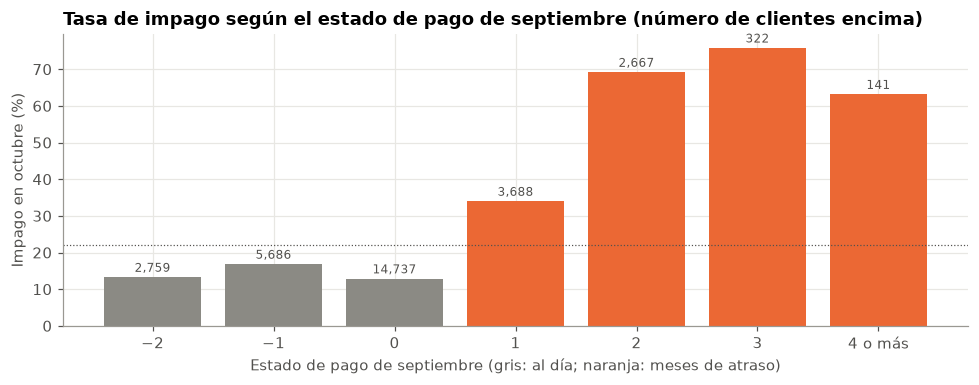

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
t = datos.groupby(datos.estado_1.clip(upper=4))['impago'].agg(['mean', 'size'])
etiquetas = {-2: '−2', -1: '−1', 0: '0', 1: '1', 2: '2', 3: '3', 4: '4 o más'}
ax.bar([etiquetas[i] for i in t.index], t['mean'] * 100, color=[GRIS] * 3 + [NARANJA] * 4)
for i, (m, n) in enumerate(zip(t['mean'], t['size'])):
    ax.text(i, m * 100 + 1.5, f'{n:,}', ha='center', fontsize=8, color=TINTA)
ax.axhline(datos.impago.mean() * 100, color=TINTA, lw=0.8, ls=':')
ax.set(title='Tasa de impago según el estado de pago de septiembre (número de clientes encima)',
       xlabel='Estado de pago de septiembre (gris: al día; naranja: meses de atraso)', ylabel='Impago en octubre (%)')
mostrar(fig, 'impago_por_estado')

- **Comportamiento del segmento griss vs naranja.** Los clientes que no presentan atrasos en sus pagos de septiembre (barras grises) no suelen terminar con impago por lo general. Mientras que los clientes que si presentan atrasos (barras naranjas) caen en impago con mayor frecuencia.

## 3. Variables

**Variables prohibidas.** Aunque predigan, hay variables que no deben decidir el acceso al crédito. El sexo, la edad, el estado civil y, en muchas regulaciones, el nivel educativo son atributos personales: usarlos para reducir una línea puede caer en suposiciones de discriminacion y difícil de defender ante un regulador. Además, los demás datos pueden funcionar como **sustitutos** de esos atributos; por eso, aunque no estén en el modelo, hay que revisar si la decisión afecta distinto a cada grupo (fairness).

In [16]:
def construir_variables(d):
    v = pd.DataFrame(index=d.index)

    # Familia de atrasos  # −2, −1 y 0 son "al día"
    atraso = d[ESTADOS].clip(lower=0)
    atraso_3m = atraso[ESTADOS[:3]]       
    v['num_atraso_u1'] = atraso['estado_1']
    v['max_atraso_u6m'] = atraso.max(axis=1)
    v['recencia_max_atraso_u6m'] = np.where(v['max_atraso_u6m'] > 0,atraso.to_numpy().argmax(axis=1), 6)
    v['num_meses_atraso_u6m'] = (atraso > 0).sum(axis=1)
    v['max_atraso_u3m'] = atraso_3m.max(axis=1)
    v['recencia_max_atraso_u3m'] = np.where(v['max_atraso_u3m'] > 0, atraso_3m.to_numpy().argmax(axis=1), 3)
    v['num_meses_atraso_u3m'] = (atraso_3m > 0).sum(axis=1)

    # Familia de Tarjetas de crédito
    deuda = d['saldo_tc_2']  # saldo tc de agosto (mes 2) 
    deuda5 = d[[f'saldo_tc_{k}' for k in range(2, 7)]].sum(axis=1)   # saldos de abril a agosto
    pagado5 = d[[f'pago_{k}' for k in range(1, 6)]].sum(axis=1)      # pagos de mayo a septiembre

    v['uso_linea_u1'] = (d['saldo_tc_1'] / d['linea']).clip(0, 1.5)
    v['uso_prom_u6m'] = (d[FACTURAS].mean(axis=1) / d['linea']).clip(0, 1.5)
    v['uso_prom_u3m'] = (d[FACTURAS[:3]].mean(axis=1) / d['linea']).clip(0, 1.5)
    v['var_uso_u1_u6'] = v['uso_linea_u1'] - (d['saldo_tc_6'] / d['linea']).clip(0, 1.5)
    v['var_uso_u1_u3'] = v['uso_linea_u1'] - (d['saldo_tc_3'] / d['linea']).clip(0, 1.5)
    v['porc_pago_deuda_u1'] = np.where(deuda > 0, d['pago_1'] / deuda.where(deuda > 0, 1), 1.0).clip(0, 1)
    v['pago_rel_5m'] = np.where(deuda5 > 0, pagado5 / deuda5.where(deuda5 > 0, 1), 1.0).clip(0, 1)
    v['log_linea'] = np.log10(d['linea'])
    v['cuenta_inactiva_u6m'] = ((d[FACTURAS] == 0).all(axis=1) & (d[PAGOS] == 0).all(axis=1)).astype(int)
    return v

def tasas(x):
    if x.nunique() <= 10:                                   # pocas categorías: una tasa por valor
        g = x.clip(upper=3)
        return ' · '.join(f'{k:g}{"+" if k == 3 and x.max() > 3 else ""}: {t:.0%}'
                          for k, t in datos.impago.groupby(g).mean().items())
    q = pd.qcut(x.rank(method='first'), 5, labels=False)    # continuas: quintiles
    return ' · '.join(f'{t:.0%}' for t in datos.impago.groupby(q).mean())

In [17]:
DERIVADAS = list(construir_variables(datos.head()).columns)
ORIGINALES = ['linea'] + ESTADOS + FACTURAS + PAGOS
X_todas = pd.concat([construir_variables(datos), datos[ORIGINALES + PROTEGIDAS]], axis=1)
y = datos['impago'].to_numpy()

descripcion = pd.DataFrame({
        'definición': ['Número de meses de atraso en el último mes (Septiembre)',
                   'Máximo atraso en los últimos 6 meses',
                   'Recencia del máximo atraso en los últimos 6 meses (0 = septiembre, 1 = agosto, 2 = julio, 3 = junio, 4 = mayo, 5 = abril, 6 = sin atraso)',
                   'Número de meses con atraso en los últimos 6 meses',
                   'Máximo atraso en los últimos 3 meses',
                   'Recencia del máximo atraso en los últimos 3 meses (0 = septiembre, 1 = agosto, 2 = julio, 3 = sin atraso)',
                   'Número de meses con atraso en los últimos 3 meses',
                   'Uso de Línea de Crédito en el último mes (Saldo TC de Septiembre ÷ Línea)',
                   'Uso de Línea promedio de los últimos 6 meses (Saldo TC promedio de Abril a Septiembre ÷ Línea)',
                   'Uso de Línea promedio de los últimos 3 meses (Saldo TC promedio de Julio a Septiembre ÷ Línea)',
                   'Variación del Uso de Línea en los últimos 6 meses (Uso de Septiembre − Uso de Abril)',
                   'Variación del Uso de Línea en los últimos 3 meses (Uso de Septiembre − Uso de Julio)',
                   'Porcentaje pagado de la deuda en el último mes (Pago de Septiembre ÷ Saldo TC de Agosto)',
                   'Porcentaje pagado de la deuda en los últimos 5 meses (Pagos de Mayo a Septiembre ÷ Saldos TC de Abril a Agosto)',
                   'Logaritmo de la línea de crédito',
                   'Sin saldo TC ni pagos en los últimos 6 meses (cuenta inactiva)'],
    'tasa de impago (por valor o por quintil)': [tasas(X_todas[c]) for c in DERIVADAS]},
    index=DERIVADAS)
descripcion

,definición,tasa de impago (por valor o por quintil)
num_atraso_u1,Número de meses de atraso en el último mes (Se...,0: 14% · 1: 34% · 2: 69% · 3+: 72%
max_atraso_u6m,Máximo atraso en los últimos 6 meses,0: 12% · 1: 25% · 2: 44% · 3+: 63%
recencia_max_atraso_u6m,Recencia del máximo atraso en los últimos 6 me...,0: 53% · 1: 41% · 2: 32% · 3+: 13%
num_meses_atraso_u6m,Número de meses con atraso en los últimos 6 meses,0: 12% · 1: 30% · 2: 39% · 3+: 60%
max_atraso_u3m,Máximo atraso en los últimos 3 meses,0: 13% · 1: 26% · 2: 50% · 3+: 64%
recencia_max_atraso_u3m,Recencia del máximo atraso en los últimos 3 me...,0: 53% · 1: 42% · 2: 33% · 3: 13%
num_meses_atraso_u3m,Número de meses con atraso en los últimos 3 meses,0: 13% · 1: 36% · 2: 44% · 3: 64%
uso_linea_u1,Uso de Línea de Crédito en el último mes (Sald...,22% · 15% · 20% · 27% · 26%
uso_prom_u6m,Uso de Línea promedio de los últimos 6 meses (...,23% · 14% · 18% · 25% · 31%
uso_prom_u3m,Uso de Línea promedio de los últimos 3 meses (...,23% · 14% · 19% · 26% · 29%


- **El atraso es la señal más fuerte.** Los clientes que caen en impago presenta señales de atraso en las dimensiones analizadas: Recencia - Frecuencia - Magnitud
- **El uso de la línea no es lineal.** El impago presenta un comportamiento no lineal en las variables de uso
- **Variacion de uso es contraintuitivo.** El grupo de mayor riesgo es el que más bajó su uso (30 %). Es lo contrario de lo que uno esperaría, porque reducir la deuda suena a buena señal.
- **Pagar más reduce el riesgo.** Quienes pagan menos de su deuda tienen 30 % a 32 % de impago, y quienes pagan más, 16 % a 17 %. La versión de 5 meses ordena de forma más pareja que la de 1 mes, porque refleja el hábito y no un mes aislado.
- **Una línea más alta, menos impago:** de 33 % en el quintil más bajo a 14 % en el más alto. La línea resume lo que el banco ya sabía del cliente al otorgarla.
- **Las cuentas inactivas no son clientes seguros:** tienen 38 % de impago, frente a 22 % del resto. Sin esta variable, el modelo las confundiría con clientes que pagan todo, porque ambos tienen uso 0 y 100 % pagado.



## 4. Particion de los datos

1. **Revisar bitacora de uso de IA - Momento 1.** 
2. **Division estratificada train-test(70/30) + validacion cruzada en train** Eleccion del umbral de reduccion de linea en las predicciones out of fold del StatifiedKFold de train

**Sustento** El impago existe para un solo mes (octubre de 2005) y todos los clientes se observan en la misma fecha, así que no hay un período posterior con el que armar una prueba fuera de tiempo (*out-of-time*). La división aleatoria estratificada es la que usa el objetivo real y los seis meses de historia sin modificarlos.

- **Test (30 %):** se aparta y se evalúa una sola vez, al final. Ninguna decisión (variables, hiperparámetros, calibración, umbral) se toma mirándolo.
- **Validación cruzada en train (5 pliegues):** cada cliente de train recibe una predicción *out-of-fold*, hecha por un modelo que no lo vio. Con esas predicciones se ajustan los hiperparámetros, se calibra y se elige el umbral de reducción de línea.
- **Estratificar** fija la tasa de impago en cada conjunto, para que las métricas no varíen por tener más o menos impagos por azar.
- **Los pliegues se crean una vez** y se reutilizan en todos los pasos, así todos los modelos se comparan sobre los mismos clientes.

In [18]:
PROPORCION_TEST = 0.30  # Proporción de clientes reservada para el test
N_PLIEGUES      = 5     # Pliegues de la validación cruzada dentro de train
SEMILLA         = 42    # Semilla para que la partición y los pliegues sean reproducibles

In [19]:
idx_train, idx_test = train_test_split(np.arange(len(datos)), test_size=PROPORCION_TEST, stratify=y, random_state=SEMILLA)
X_train, X_test = X_todas.iloc[idx_train], X_todas.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
assert not set(idx_train) & set(idx_test), 'Hay clientes en train y en test a la vez'

# Pliegues de validación cruzada: posiciones dentro de X_train, se reutilizan en todo el notebook
pliegues = list(StratifiedKFold(N_PLIEGUES, shuffle=True, random_state=SEMILLA).split(X_train, y_train))

conjuntos = [('train', y_train), ('test', y_test)] + [(f'pliegue {k + 1} (validación)', y_train[val]) for k, (_, val) in enumerate(pliegues)]
pd.DataFrame([(n, len(v), int(v.sum()), pct(v.mean(), 2)) for n, v in conjuntos],
             columns=['conjunto', 'clientes', 'impagos', 'tasa de impago']).set_index('conjunto')

,clientes,impagos,tasa de impago
conjunto,,,
train,21000,4645,22.12 %
test,9000,1991,22.12 %
pliegue 1 (validación),4200,929,22.12 %
pliegue 2 (validación),4200,929,22.12 %
pliegue 3 (validación),4200,929,22.12 %
pliegue 4 (validación),4200,929,22.12 %
pliegue 5 (validación),4200,929,22.12 %


## 5. Feature selection

**Sustento** Este paso es fundamental para garantizar que las variables que ingresen a los modelos sean significativas



La selección siguientes pasos para el desarrollo de modelos de riesgo crediticio:

1. **Inventario:** qué mide cada candidata, con qué ventana se calcula, qué sentido se espera y cuáles se retiran por criterio experto.
2. **Filtro univariado:** faltantes, concentración y variabilidad.
3. **Estabilidad (PSI):** si la distribución de la variable cambia entre meses.
4. **Relación con el objetivo:** IV y Gini por pliegue.
5. **Correlación:** entre dos variables muy correlacionadas se queda la de mayor Gini; el VIF confirma que no queda colinealidad.
6. **Decisión por variable:** una tabla con la prueba y el valor que respaldan cada decisión.

Cada paso evalúa solo las variables que pasaron el anterior. La tabla de 5.6 muestra en qué paso salió cada una.

**Dos adaptaciones a estos datos:**

- **No hay muestra fuera de tiempo.** Aquí se calculan entre los 5 pliegues de validación de train, porque el test se reserva para la evaluación final.
- **El PSI se mide desplazando la ventana.** Todos los clientes se observan en septiembre, pero las variables mensuales permiten recalcular cada candidata como si la foto se hubiera tomado uno a cinco meses antes. El PSI compara esas versiones con la de septiembre, que es la que usa el modelo. Solo se puede medir en variables cuya ventana cabe en los seis meses después de desplazarla.

In [20]:
MAX_FALTANTES      = 0.75   # Se descarta con más del 75 % de faltantes
MAX_CONCENTRACION  = 0.85   # Se descarta si un solo valor concentra más del 85 % de los clientes
MIN_COEF_VARIACION = 0.04   # Se descarta una variable numérica con coeficiente de variación menor a 4 %
PSI_REVISAR        = 0.10   # PSI entre 0.10 y 0.20: avanza con revisión
PSI_EXCLUIR        = 0.20   # PSI mayor a 0.20: se excluye salvo justificación técnica
MIN_IV             = 0.02   # Se descarta con IV mínimo entre pliegues ≤ 2 %
MIN_GINI           = 0.03   # Se descarta con Gini mínimo entre pliegues ≤ 3 %
MAX_CV_GINI        = 0.80   # Se descarta si el coeficiente de variación del Gini entre pliegues es ≥ 80 %
MAX_CORRELACION    = 0.60   # Correlación máxima para la logística de referencia (0.85 para aprendizaje automático)
N_GRUPOS           = 10     # Grupos (deciles) para calcular WoE, IV y PSI en variables continuas

### 5.1 Inventario de candidatas

Las candidatas son las 16 variables derivadas y las 19 originales (línea, estados, saldos y pagos). Quedan fuera el ID y las variables protegidas (sexo, edad, estado civil y educación), que solo se usan para revisar la equidad.


**Exclusión por criterio experto.** Los seis estados de pago originales (`estado_1` a `estado_6`) se retiran antes de medirlos. Los motivos vienen de la calidad de datos (sección 2), no de los resultados de esta sección:

- **Los códigos -2 y 0 no están documentados.**
- **Mezclan dos cosas en una sola escala.** Los valores -2, -1 y 0 son clientes sin atraso con distinto uso de la tarjeta. Según el código de agosto, el uso mediano de la línea en los seis meses es 0.5 %, 2.3 % y 53 %. Los valores 1 a 9 son meses de atraso. Una logística los trataría como una escala numérica (-2 < -1 < 0 < 1 …), y su coeficiente no se podría explicar como motivo para reducir una línea.

La señal de atraso se conserva en las variables derivadas, que cuentan los meses con atraso o miden cuándo ocurrió. El uso se mide directamente con saldo ÷ línea.


In [21]:
VENTANA = {'num_atraso_u1': 1, 'max_atraso_u6m': 6, 'recencia_max_atraso_u6m': 6, 'num_meses_atraso_u6m': 6,
           'max_atraso_u3m': 3, 'recencia_max_atraso_u3m': 3, 'num_meses_atraso_u3m': 3,
           'uso_linea_u1': 1, 'uso_prom_u6m': 6, 'uso_prom_u3m': 3, 'var_uso_u1_u6': 6, 'var_uso_u1_u3': 3,
           'porc_pago_deuda_u1': 2, 'pago_rel_5m': 6, 'log_linea': None, 'cuenta_inactiva_u6m': 6, 'linea': None}
VENTANA |= {f'{fam}_{k}': k for fam in ('estado', 'saldo_tc', 'pago') for k in range(1, 7)}

SUBE, BAJA = 'sube el riesgo', 'baja el riesgo'
SENTIDO = {'num_atraso_u1': SUBE, 'max_atraso_u6m': SUBE, 'recencia_max_atraso_u6m': BAJA, 'num_meses_atraso_u6m': SUBE,
           'max_atraso_u3m': SUBE, 'recencia_max_atraso_u3m': BAJA, 'num_meses_atraso_u3m': SUBE,
           'uso_linea_u1': SUBE, 'uso_prom_u6m': SUBE, 'uso_prom_u3m': SUBE, 'porc_pago_deuda_u1': BAJA,
           'pago_rel_5m': BAJA, 'log_linea': BAJA, 'cuenta_inactiva_u6m': SUBE, 'linea': BAJA}
SENTIDO |= {f'estado_{k}': SUBE for k in range(1, 7)} | {f'pago_{k}': BAJA for k in range(1, 7)}

CANDIDATAS = DERIVADAS + ORIGINALES
X_cand = X_train[CANDIDATAS]

# Exclusión por criterio experto, decidida con la calidad de datos de la sección 2 y antes de medir las variables
EXCLUSION_EXPERTA = {e: 'códigos -2 y 0 sin documentar; mezcla uso de la tarjeta (-2, -1, 0) con meses de atraso (1 a 9)' for e in ESTADOS}
inventario = pd.DataFrame({
    'origen': ['derivada' if c in DERIVADAS else 'original' for c in CANDIDATAS],
    'ventana (meses)': [VENTANA[c] if VENTANA[c] else 'sin fecha' for c in CANDIDATAS],
    'sentido esperado': [SENTIDO.get(c, 'sin hipótesis') for c in CANDIDATAS],
    'exclusión experta': [EXCLUSION_EXPERTA.get(c, '') for c in CANDIDATAS]}, index=CANDIDATAS)
pasan_experto = [c for c in CANDIDATAS if c not in EXCLUSION_EXPERTA]

print(f'{len(CANDIDATAS)} candidatas, {len(EXCLUSION_EXPERTA)} retiradas por criterio experto, {len(pasan_experto)} siguen | '
      f'{int(y_train.sum()):,} impagos en train → '
      f'presupuesto de {int(y_train.sum()) // 20} a {int(y_train.sum()) // 10} parámetros')
inventario

35 candidatas, 6 retiradas por criterio experto, 29 siguen | 4,645 impagos en train → presupuesto de 232 a 464 parámetros


,origen,ventana (meses),sentido esperado,exclusión experta
num_atraso_u1,derivada,1,sube el riesgo,
max_atraso_u6m,derivada,6,sube el riesgo,
recencia_max_atraso_u6m,derivada,6,baja el riesgo,
num_meses_atraso_u6m,derivada,6,sube el riesgo,
max_atraso_u3m,derivada,3,sube el riesgo,
recencia_max_atraso_u3m,derivada,3,baja el riesgo,
num_meses_atraso_u3m,derivada,3,sube el riesgo,
uso_linea_u1,derivada,1,sube el riesgo,
uso_prom_u6m,derivada,6,sube el riesgo,
uso_prom_u3m,derivada,3,sube el riesgo,


### 5.2 Filtro univariado

Una variable que casi no cambia entre clientes no puede separarlos. Por variable se mide:

- **Faltantes:** proporción de clientes sin dato.
- **Concentración:** proporción de clientes en el valor más frecuente.
- **Desviación estándar y coeficiente de variación** (desviación ÷ media). El coeficiente solo se calcula en variables sin valores negativos, porque con negativos la media puede quedar cerca de cero y el cociente pierde sentido.

In [22]:
def filtro_univariado(x):
    media, de = x.mean(), x.std()
    return pd.Series({'faltantes': x.isna().mean(),
                      'concentración': x.value_counts(normalize=True, dropna=False).iloc[0],
                      'desv. estándar': de,
                      'coef. variación': de / media if x.min() >= 0 and media > 0 else np.nan})

univariado = X_cand[pasan_experto].apply(filtro_univariado).T
univariado['falla'] = [', '.join(regla for regla, falla in [
        ('faltantes', r['faltantes'] > MAX_FALTANTES),
        ('concentración', r['concentración'] > MAX_CONCENTRACION),
        ('sin variación', r['desv. estándar'] == 0),
        ('coef. variación', r['coef. variación'] < MIN_COEF_VARIACION)] if falla)
    for _, r in univariado.iterrows()]

pasan_univariado = univariado.index[univariado['falla'] == ''].tolist()
print(f'Pasan el filtro univariado: {len(pasan_univariado)} de {len(pasan_experto)}')
univariado.round(3)

Pasan el filtro univariado: 28 de 29


,faltantes,concentración,desv. estándar,coef. variación,falla
num_atraso_u1,0.0,0.771,0.760,2.122,
max_atraso_u6m,0.0,0.662,1.066,1.560,
recencia_max_atraso_u6m,0.0,0.662,2.411,0.548,
num_meses_atraso_u6m,0.0,0.662,1.556,1.855,
max_atraso_u3m,0.0,0.717,0.980,1.765,
recencia_max_atraso_u3m,0.0,0.717,1.150,0.495,
num_meses_atraso_u3m,0.0,0.717,0.949,1.832,
uso_linea_u1,0.0,0.086,0.399,0.948,
uso_prom_u6m,0.0,0.035,0.347,0.934,
uso_prom_u3m,0.0,0.050,0.382,0.938,


- **Ninguna candidata tiene faltantes ni desviación cero.**
- **Solo `cuenta_inactiva_u6m` falla:** el 97.3 % de los clientes de train tiene valor 0. Sus clientes tienen más impago (38 % frente a 22 %)

### 5.3 Estabilidad en el tiempo (PSI)

El PSI compara la proporción de clientes por grupo entre una distribución de referencia ($p$) y otra a evaluar ($q$):

$$PSI = \sum_{\text{grupos}} (p - q)\,\ln\frac{p}{q}$$

- **Referencia:** la variable calculada con la ventana que termina en septiembre (la que ve el modelo).
- **Evaluación:** la misma variable calculada con la ventana desplazada 1 a 5 meses hacia atrás. Por ejemplo, con un desplazamiento de 2 meses, "último mes" pasa a ser julio.
- **Grupos:** deciles de la referencia, o un grupo por valor si la variable tiene pocos valores. Se fijan con la referencia y se aplican sin cambios a la evaluación.
- Se conserva el **PSI máximo** y el mes que lo produjo. También se muestra el PSI contra agosto, la comparación más cercana.

Son los mismos clientes en meses distintos, así que el PSI mide cuánto cambia el comportamiento entre meses, no un cambio de población.

Se evalúan las 28 variables que pasaron el filtro univariado.

In [23]:
MESES = ['septiembre', 'agosto', 'julio', 'junio', 'mayo', 'abril']

def cortes_fijos(x, n=N_GRUPOS):
    # Un grupo por valor si hay pocos valores distintos; deciles en otro caso
    valores = np.unique(x)
    return valores[1:] if len(valores) <= 12 else np.unique(np.quantile(x, np.linspace(0, 1, n + 1)[1:-1]))

def asignar_grupo(x, cortes):
    return np.searchsorted(cortes, x, side='right')

def psi(referencia, evaluacion, eps=1e-4):
    cortes = cortes_fijos(referencia)
    k = len(cortes) + 1
    p = np.clip(np.bincount(asignar_grupo(referencia, cortes), minlength=k) / len(referencia), eps, None)
    q = np.clip(np.bincount(asignar_grupo(evaluacion, cortes), minlength=k) / len(evaluacion), eps, None)
    return float(np.sum((p - q) * np.log(p / q)))

def desplazar(d, s):
    # Datos como se veían s meses antes: el mes k + s pasa a ocupar la posición k
    e = d.copy()
    for familia in (ESTADOS, FACTURAS, PAGOS):
        for k in range(1, 7 - s):
            e[familia[k - 1]] = d[familia[k - 1 + s]].to_numpy()
    return e

datos_train = datos.iloc[idx_train]
psi_por_mes = {}
for s in range(1, 6):
    d_s = desplazar(datos_train, s)
    X_s = pd.concat([construir_variables(d_s), d_s[ORIGINALES]], axis=1)
    evaluables = [c for c in pasan_univariado if VENTANA[c] is not None and VENTANA[c] <= 6 - s]
    psi_por_mes[MESES[s]] = {c: psi(X_cand[c], X_s[c]) for c in evaluables}
psi_por_mes = pd.DataFrame(psi_por_mes).reindex(pasan_univariado)

estabilidad = pd.DataFrame({'PSI vs agosto': psi_por_mes['agosto'],
                            'PSI máximo': psi_por_mes.max(axis=1),
                            'mes del máximo': psi_por_mes.dropna(how='all').idxmax(axis=1)})
estabilidad['lectura'] = np.select([estabilidad['PSI máximo'] > PSI_EXCLUIR, estabilidad['PSI máximo'] > PSI_REVISAR,
                                    estabilidad['PSI máximo'].notna()], ['excluir', 'revisar', 'estable'], 'no evaluable')
estabilidad.sort_values('PSI máximo', ascending=False).round(3)

,PSI vs agosto,PSI máximo,mes del máximo,lectura
num_atraso_u1,0.599,0.912,mayo,excluir
max_atraso_u3m,0.247,0.416,junio,excluir
porc_pago_deuda_u1,0.002,0.158,junio,revisar
uso_linea_u1,0.005,0.152,abril,revisar
pago_1,0.004,0.150,abril,revisar
pago_2,0.045,0.132,julio,revisar
recencia_max_atraso_u3m,0.026,0.090,junio,estable
uso_prom_u3m,0.012,0.080,junio,estable
saldo_tc_1,0.005,0.072,abril,estable
num_meses_atraso_u3m,0.020,0.070,junio,estable


Las dos variables con PSI mayor a 0.20 dependen del **valor** del estado de pago de septiembre. Antes de decidir, se revisa si el cambio viene del comportamiento de los clientes o de cómo se codificó el dato.

In [24]:
codigos = pd.DataFrame({MESES[k]: {'con atraso (> 0)': (datos_train[e] > 0).mean(),
                                   'Atraso 1': (datos_train[e] == 1).mean(),
                                   'Atraso 2': (datos_train[e] == 2).mean()}
                        for k, e in enumerate(ESTADOS)})
display(codigos.map(pct))

# max_atraso_u6m no se puede desplazar (usa los 6 meses), pero hereda el código 1 de septiembre
max_es_1 = X_cand['max_atraso_u6m'] == 1
solo_septiembre = (datos_train['estado_1'] == 1) & (datos_train[ESTADOS[1:]].clip(lower=0).max(axis=1) == 0)
n_solo = (max_es_1 & solo_septiembre).sum()
print(f'Clientes con max_atraso_u6m = 1: {max_es_1.sum():,} | de ellos, solo por el código 1 de septiembre: {n_solo:,} ({pct(n_solo / max_es_1.sum())})')

EXCLUIDAS_PSI = estabilidad.index[estabilidad['lectura'] == 'excluir'].tolist() + ['max_atraso_u6m']
pasan_estabilidad = [c for c in pasan_univariado if c not in EXCLUIDAS_PSI]
print(f'Excluidas por estabilidad: {EXCLUIDAS_PSI} | pasan: {len(pasan_estabilidad)}')

,septiembre,agosto,julio,junio,mayo,abril
con atraso (> 0),22.9 %,14.8 %,14.1 %,11.8 %,9.9 %,10.4 %
Atraso 1,12.5 %,0.1 %,0.0 %,0.0 %,0.0 %,0.0 %
Atraso 2,9.0 %,13.1 %,12.8 %,10.7 %,8.8 %,9.3 %


Clientes con max_atraso_u6m = 1: 1,200 | de ellos, solo por el código 1 de septiembre: 1,179 (98.2 %)
Excluidas por estabilidad: ['max_atraso_u3m', 'num_atraso_u1', 'max_atraso_u6m'] | pasan: 25


- **Dos variables superan 0.20 y las dos usan el valor del estado de pago de septiembre:** `num_atraso_u1` (0.912) y `max_atraso_u3m` (0.416). Incluso contra agosto, el mes más cercano, `num_atraso_u1` da 0.599.
- **La causa es la codificación, no el comportamiento.** El código de atraso 1 mes aparece en el 12.5 % de los clientes en septiembre y en 0.1 % o menos en los meses anteriores, donde el atraso empieza en 2. Con ese código, la proporción de clientes con atraso salta de 14.8 % en agosto a 22.9 % en septiembre.
- **Se excluyen las dos y también `max_atraso_u6m`.** Su PSI no se puede medir porque usa los seis meses, pero 1,179 de los 1,200 clientes con valor 1 (98.2 %) lo tienen solo por el código 1 de septiembre. Si en operación el atraso se codifica como en los meses anteriores, estas variables cambian de distribución y el modelo recibe datos distintos a los que aprendió.
- **Cuatro quedan en revisión (PSI entre 0.10 y 0.20):** `porc_pago_deuda_u1` (0.158), `uso_linea_u1` (0.152), `pago_1` (0.150) y `pago_2` (0.132). Contra agosto, las cuatro están por debajo de 0.05. El PSI sube al compararlas con meses lejanos (abril a julio), así que el pago y el uso cambian de forma gradual durante el semestre, no de golpe.
- **10 variables no se pueden evaluar:** usan los seis meses o la línea, que no tiene fecha. Su estabilidad queda pendiente hasta tener datos de otros períodos.

### 5.4 Relación con el objetivo (IV y Gini)

Para cada candidata y cada pliegue de train:

1. Con los otros 4 pliegues se fijan los grupos (deciles o valores) y se calcula el **peso de evidencia** de cada grupo: $WoE = \ln\left(\frac{\%\ \text{no impago}}{\%\ \text{impago}}\right)$. Un WoE negativo indica un grupo con más impagos que el promedio. Se suma 0.5 a cada conteo para que ningún grupo vacío dé un logaritmo infinito.
2. En el pliegue de validación se mide:
   - el **Gini** del puntaje $-WoE$: $Gini = 2 \times AUC - 1$;
   - el **valor de información**: $IV = \sum (\%\ \text{no impago} - \%\ \text{impago}) \times WoE$.

Así cada medida sale de clientes que no se usaron para fijar los grupos. Se reportan el IV mínimo, el Gini medio, el Gini mínimo y el coeficiente de variación del Gini entre los 5 pliegues. El **sentido observado** es el signo de la correlación de Spearman con el impago en train y se compara con el sentido esperado del inventario.

Se evalúan las 25 variables que pasaron la prueba de estabilidad.

In [25]:
def woe_iv(grupo, y, k, suavizado=0.5):
    impagos = np.bincount(grupo, weights=y, minlength=k)
    no_impagos = np.bincount(grupo, minlength=k) - impagos
    p_no = (no_impagos + suavizado) / (no_impagos.sum() + suavizado * k)
    p_si = (impagos + suavizado) / (impagos.sum() + suavizado * k)
    woe = np.log(p_no / p_si)
    return woe, float(np.sum((p_no - p_si) * woe))

def bivariado(x, y, pliegues):
    x = np.asarray(x)
    ginis, ivs = [], []
    for ajuste, valida in pliegues:
        cortes = cortes_fijos(x[ajuste])
        k = len(cortes) + 1
        woe, _ = woe_iv(asignar_grupo(x[ajuste], cortes), y[ajuste], k)
        grupo_val = asignar_grupo(x[valida], cortes)
        ginis.append(2 * roc_auc_score(y[valida], -woe[grupo_val]) - 1)
        ivs.append(woe_iv(grupo_val, y[valida], k)[1])
    ginis = np.array(ginis)
    return pd.Series({'IV mínimo': min(ivs), 'Gini medio': ginis.mean(), 'Gini mínimo': ginis.min(),
                      'CV del Gini': ginis.std() / abs(ginis.mean())})

relacion = pd.DataFrame({c: bivariado(X_cand[c], y_train, pliegues) for c in pasan_estabilidad}).T
impago_train = pd.Series(y_train, index=X_cand.index)
relacion['sentido observado'] = [SUBE if X_cand[c].corr(impago_train, method='spearman') > 0 else BAJA for c in pasan_estabilidad]
relacion['sentido esperado'] = inventario['sentido esperado']
relacion['falla'] = [', '.join(regla for regla, falla in [
        ('IV', r['IV mínimo'] <= MIN_IV), ('Gini', r['Gini mínimo'] <= MIN_GINI), ('CV del Gini', r['CV del Gini'] >= MAX_CV_GINI)] if falla)
    for _, r in relacion.iterrows()]
con_hipotesis = relacion['sentido esperado'] != 'sin hipótesis'
contradicen = relacion.index[con_hipotesis & (relacion['sentido esperado'] != relacion['sentido observado'])].tolist()
pasan_bivariado = relacion.index[relacion['falla'] == ''].tolist()
print(f'Pasan la prueba bivariada: {len(pasan_bivariado)} de {len(pasan_estabilidad)} | '
      f'sentido observado contrario al esperado: {contradicen or "ninguna"}')
relacion.sort_values('Gini medio', ascending=False).round(3)

Pasan la prueba bivariada: 19 de 25 | sentido observado contrario al esperado: ninguna


,IV mínimo,Gini medio,Gini mínimo,CV del Gini,sentido observado,sentido esperado,falla
num_meses_atraso_u6m,0.818,0.462,0.444,0.033,sube el riesgo,sube el riesgo,
recencia_max_atraso_u6m,0.725,0.443,0.421,0.039,baja el riesgo,baja el riesgo,
num_meses_atraso_u3m,0.745,0.434,0.411,0.044,sube el riesgo,sube el riesgo,
recencia_max_atraso_u3m,0.695,0.423,0.400,0.045,baja el riesgo,baja el riesgo,
linea,0.166,0.240,0.219,0.063,baja el riesgo,baja el riesgo,
log_linea,0.166,0.240,0.219,0.063,baja el riesgo,baja el riesgo,
porc_pago_deuda_u1,0.166,0.214,0.165,0.159,baja el riesgo,baja el riesgo,
pago_1,0.140,0.212,0.193,0.070,baja el riesgo,baja el riesgo,
pago_2,0.131,0.209,0.192,0.088,baja el riesgo,baja el riesgo,
uso_prom_u6m,0.114,0.197,0.179,0.071,sube el riesgo,sube el riesgo,


- **El atraso es la familia que más separa:** Gini medio entre 0.42 y 0.46 e IV mínimo entre 0.70 y 0.82. La más fuerte es `num_meses_atraso_u6m` (Gini medio 0.462).
- **Los saldos (`saldo_tc_1` a `saldo_tc_6`) no pasan:** su IV mínimo va de 0.008 a 0.019, por debajo de 2 %, y el sentido de la relación cambia según el mes. El saldo solo no dice si el cliente puede pagarlo. Esa información ya está en el uso (saldo ÷ línea) y en el pago.
- **Las relaciones son estables entre pliegues:** el mayor coeficiente de variación del Gini entre las que pasan es 0.191 (`var_uso_u1_u3`), lejos del corte de 0.80.
- **Ninguna variable contradice el sentido esperado.** En la variación del uso, que no tenía hipótesis, bajar el uso se asocia a más impago, como se vio en la sección 3.

### 5.5 Correlación

Dos variables que miden casi lo mismo no aportan información nueva. Además, reparten la importancia entre ellas y hacen más difícil explicar el modelo. Se usa la correlación de Spearman, que capta relaciones monótonas aunque no sean lineales y no se afecta por valores extremos.

**Umbral:** 0.60, el de la guía para modelos clásicos, porque el primer modelo es una regresión logística de referencia. Para un modelo de aprendizaje automático la guía usa 0.85.

**Regla:** las variables que pasaron los filtros anteriores se ordenan por Gini medio (con empate, menor variación del Gini). Se recorren en ese orden y una variable entra solo si su correlación con todas las ya elegidas es menor o igual al umbral. **Entre dos variables correlacionadas siempre se queda la de mayor Gini.**

El **VIF** mide cuánto de una variable se explica con las demás en conjunto: VIF ≤ 5 aceptable, entre 5 y 10 revisar, más de 10 excluir o transformar.

In [26]:
sobreviven = pasan_bivariado
correlacion = X_cand[sobreviven].corr(method='spearman').abs()

orden = relacion.loc[sobreviven].sort_values(['Gini medio', 'CV del Gini'], ascending=[False, True], kind='stable').index
VARIABLES_MODELO, redundantes = [], {}
for c in orden:
    choque = [e for e in VARIABLES_MODELO if correlacion.loc[c, e] > MAX_CORRELACION]
    if choque:
        elegida = choque[0]
        redundantes[c] = {'Gini': relacion.loc[c, 'Gini medio'], 'redundante con': elegida,
                          'Gini de la elegida': relacion.loc[elegida, 'Gini medio'],
                          'correlación': correlacion.loc[c, elegida]}
    else:
        VARIABLES_MODELO.append(c)

assert all(r['Gini de la elegida'] >= r['Gini'] for r in redundantes.values()), 'Se excluyó una variable con más Gini'

final = correlacion.loc[VARIABLES_MODELO, VARIABLES_MODELO].mask(np.eye(len(VARIABLES_MODELO), dtype=bool), 0)
vif = pd.Series(np.diag(np.linalg.inv(X_cand[VARIABLES_MODELO].corr().to_numpy())), index=VARIABLES_MODELO)
print(f'{len(sobreviven)} variables llegan a esta etapa, {len(VARIABLES_MODELO)} quedan | '
      f'correlación máxima entre las elegidas: {final.max().max():.3f}')
display(pd.DataFrame(redundantes).T.infer_objects().round(3))
vif.sort_values(ascending=False).round(2).to_frame('VIF').T

19 variables llegan a esta etapa, 11 quedan | correlación máxima entre las elegidas: 0.577


,Gini,redundante con,Gini de la elegida,correlación
recencia_max_atraso_u6m,0.443,num_meses_atraso_u6m,0.462,0.954
num_meses_atraso_u3m,0.434,num_meses_atraso_u6m,0.462,0.907
recencia_max_atraso_u3m,0.423,num_meses_atraso_u6m,0.462,0.872
linea,0.240,log_linea,0.240,1.000
uso_prom_u6m,0.197,porc_pago_deuda_u1,0.214,0.695
pago_rel_5m,0.172,porc_pago_deuda_u1,0.214,0.849
uso_prom_u3m,0.171,porc_pago_deuda_u1,0.214,0.715
uso_linea_u1,0.150,porc_pago_deuda_u1,0.214,0.727


,var_uso_u1_u6,var_uso_u1_u3,porc_pago_deuda_u1,pago_2,pago_1,log_linea,pago_3,num_meses_atraso_u6m,pago_4,pago_6,pago_5
VIF,1.84,1.73,1.3,1.28,1.26,1.25,1.21,1.21,1.16,1.12,1.11


- **De 19 variables, 8 salen por correlación y quedan 11.** Cada una choca con otra de mayor Gini (correlación entre paréntesis):
  - Atraso: se queda `num_meses_atraso_u6m` (Gini 0.462) y salen `recencia_max_atraso_u6m` (0.443; 0.95), `num_meses_atraso_u3m` (0.434; 0.91) y `recencia_max_atraso_u3m` (0.423; 0.87).
  - Pago y uso: se queda `porc_pago_deuda_u1` (0.214) y salen `uso_prom_u6m` (0.197; 0.70), `pago_rel_5m` (0.172; 0.85), `uso_prom_u3m` (0.171; 0.72) y `uso_linea_u1` (0.150; 0.73). Quien paga toda su deuda casi no usa la línea, así que el porcentaje pagado también resume el uso.
  - Línea: `linea` y `log_linea` tienen correlación 1.00 y el mismo Gini (0.240). Se conserva `log_linea`.
- **No queda colinealidad:** la correlación más alta entre las 11 es 0.577 y ningún VIF pasa de 1.84, muy por debajo de 5.
- **Quedan los seis pagos mensuales.** Entre ellos ninguna correlación llega a 0.60, así que cada mes aporta algo propio. La depuración del modelo (sección 6.1) decide cuáles se quedan.

### 5.6 Decisión por variable

La tabla resume, para cada candidata, el paso en el que salió o la lectura con la que avanza, junto con los valores medidos. Las columnas de los pasos a los que una variable no llegó quedan vacías. `VARIABLES_MODELO` es la lista que usa el modelo de referencia.

In [27]:
def decision(c):
    if c in EXCLUSION_EXPERTA:
        return 'excluida', 'criterio experto: códigos sin documentar'
    if univariado.loc[c, 'falla']:
        return 'excluida', f"univariado: {univariado.loc[c, 'falla']}"
    if c in EXCLUIDAS_PSI:
        return 'excluida', 'estabilidad: código 1 solo en septiembre'
    if relacion.loc[c, 'falla']:
        return 'excluida', f"bivariado: {relacion.loc[c, 'falla']}"
    if c in redundantes:
        return 'excluida', f"correlación con {redundantes[c]['redundante con']}"
    if estabilidad.loc[c, 'lectura'] == 'revisar':
        return 'avanza', 'PSI entre 0.10 y 0.20: vigilar'
    return 'avanza', ''

resumen = pd.concat([inventario['origen'], univariado['concentración'], estabilidad['PSI máximo'],
                     relacion[['IV mínimo', 'Gini medio', 'Gini mínimo']]], axis=1).reindex(CANDIDATAS)
resumen[['decisión', 'motivo']] = [decision(c) for c in CANDIDATAS]
display(resumen.groupby('decisión')['motivo'].value_counts().to_frame('variables'))
resumen.sort_values(['decisión', 'Gini medio'], ascending=[True, False]).round(3)

variables
decisión motivo                                             
avanza                                                     8
         PSI entre 0.10 y 0.20: vigilar                    3
excluida criterio experto: códigos sin documentar          6
         bivariado: IV                                     5
         correlación con porc_pago_deuda_u1                4
         estabilidad: código 1 solo en septiembre          3
         correlación con num_meses_atraso_u6m              3
         univariado: concentración                         1
         correlación con log_linea                         1
         bivariado: IV, Gini                               1

,origen,concentración,PSI máximo,IV mínimo,Gini medio,Gini mínimo,decisión,motivo
num_meses_atraso_u6m,derivada,0.662,NaN,0.818,0.462,0.444,avanza,
log_linea,derivada,0.112,NaN,0.166,0.240,0.219,avanza,
porc_pago_deuda_u1,derivada,0.333,0.158,0.166,0.214,0.165,avanza,PSI entre 0.10 y 0.20: vigilar
pago_1,original,0.173,0.150,0.140,0.212,0.193,avanza,PSI entre 0.10 y 0.20: vigilar
pago_2,original,0.179,0.132,0.131,0.209,0.192,avanza,PSI entre 0.10 y 0.20: vigilar
pago_3,original,0.199,0.027,0.107,0.186,0.178,avanza,
var_uso_u1_u6,derivada,0.069,NaN,0.088,0.168,0.154,avanza,
pago_6,original,0.241,NaN,0.085,0.161,0.147,avanza,
pago_4,original,0.212,0.002,0.068,0.159,0.133,avanza,
pago_5,original,0.224,0.001,0.069,0.152,0.122,avanza,


- **De 35 candidatas quedan 11.** Salen 6 por criterio experto, 1 por el filtro univariado, 3 por estabilidad, 6 por la prueba bivariada y 8 por correlación.
- **Tres de las 11 avanzan con vigilancia** por su PSI entre 0.10 y 0.20: `porc_pago_deuda_u1`, `pago_1` y `pago_2`.
- **El uso de la línea no tiene una variable propia.** Queda representado por el porcentaje pagado de la deuda y por las dos variaciones del uso.

## 6. Modelo de referencia (baseline): regresión logística

**Sustento** Antes de probar un modelo complejo hay que tener una referencia sencilla, explicable y con desempeño conocido. La regresión logística es el estándar en riesgo de crédito: cada coeficiente dice cuánto y en qué sentido mueve el riesgo una variable, y su salida es una probabilidad que se puede comparar con la tasa observada.

**Cómo se construye:**

- **Variables:** se parte de las 11 de `VARIABLES_MODELO`. Los pagos se transforman con $\log(1 + x)$, porque son montos con cola larga y unos pocos clientes con pagos enormes dominarían los coeficientes. Esta transformación no aprende nada de los datos, así que no filtra información entre muestras.
- **Estandarización:** cada variable se centra y se divide por su desviación estándar, ajustada solo con los datos de entrenamiento de cada pliegue. Así los coeficientes son comparables: miden el efecto de mover la variable una desviación estándar.
- **Sin regularización:** con 4,645 impagos para 12 parámetros (11 variables y el intercepto) hay unos 390 impagos por parámetro, muy por encima de los 10 a 20 que pide la guía. No hace falta penalizar.

**Cómo se evalúa:**

- **Fuera de pliegue (*out-of-fold*):** con los mismos 5 pliegues de la sección 4, cada cliente de train recibe la probabilidad de un modelo que no lo vio. Las métricas se calculan sobre esas predicciones.
- **El test no se usa aquí.** Se evalúa una sola vez al final, con el modelo de referencia y el modelo final juntos.

In [28]:
P_MAX           = 0.05                                     # Valor p máximo para que una variable se quede en la logística
UMBRAL_COSTO    = COSTO_FP / (COSTO_FP + COSTO_FN)         # Corte de mínimo costo esperado si la probabilidad está calibrada (1/6)
FRACCIONES_TOP  = [0.10, 0.20]                             # Porcentaje superior de clientes, ordenados por riesgo, para lift, precisión y recall
N_BOOTSTRAP     = 1000                                     # Réplicas para los intervalos de confianza
GINI_REFERENCIA = (0.40, 0.50)                             # Rango de Gini de la guía: muestra de construcción, población total, evento específico

def preparar(X, variables):
    X = X[variables].copy()
    montos = [c for c in variables if c.startswith('pago_')]
    X[montos] = np.log1p(X[montos])
    return X

baseline = Pipeline([('escala', StandardScaler()), ('logistica', LogisticRegression(penalty=None, max_iter=1000))])
print(f'Corte de costo: {UMBRAL_COSTO:.4f} → reducir la línea si la probabilidad de impago supera 1/6')

Corte de costo: 0.1667 → reducir la línea si la probabilidad de impago supera 1/6


### 6.1 Coeficientes y depuración

Por variable se reporta:

- **Coeficiente y razón de momios (*odds ratio*)** por una desviación estándar: cuánto se multiplican las chances de impago al mover la variable una desviación.
- **Sentido:** el signo del coeficiente frente al sentido esperado del inventario. Una inversión puede venir de colinealidad o de un efecto que la variable solo muestra junto con las demás, y hay que investigarla.
- **Estabilidad:** coeficiente de variación del coeficiente entre los 5 pliegues.


In [29]:
from scipy.stats import norm

def coeficientes_logistica(variables):
    X = preparar(X_train, variables)
    modelo = clone(baseline).fit(X, y_train)
    Z = np.column_stack([np.ones(len(X)), modelo[0].transform(X)])
    beta = np.r_[modelo[-1].intercept_, modelo[-1].coef_[0]]
    p = modelo.predict_proba(X)[:, 1]
    error = np.sqrt(np.diag(np.linalg.inv(Z.T @ (Z * (p * (1 - p))[:, None]))))[1:]
    por_pliegue = np.array([clone(baseline).fit(X.iloc[ajuste], y_train[ajuste])[-1].coef_[0] for ajuste, _ in pliegues])
    tabla = pd.DataFrame({'coeficiente': beta[1:], 'odds ratio (1 desv.)': np.exp(beta[1:]), 'error est.': error,
                          'valor p': 2 * norm.sf(np.abs(beta[1:] / error)),
                          'CV entre pliegues': por_pliegue.std(axis=0) / np.abs(por_pliegue.mean(axis=0))}, index=variables)
    tabla['sentido del coeficiente'] = np.where(tabla['coeficiente'] > 0, SUBE, BAJA)
    tabla['sentido esperado'] = inventario.loc[variables, 'sentido esperado']
    return modelo, tabla.sort_values('coeficiente', key=np.abs, ascending=False)

def invertidas(tabla):
    con_hipotesis = tabla['sentido esperado'] != 'sin hipótesis'
    return tabla.index[con_hipotesis & (tabla['sentido esperado'] != tabla['sentido del coeficiente'])].tolist()

_, coef_completo = coeficientes_logistica(VARIABLES_MODELO)
print(f'Modelo con {len(VARIABLES_MODELO)} variables | signo contrario al esperado: {invertidas(coef_completo) or "ninguno"} | '
      f'no significativas (p ≥ {P_MAX}): {coef_completo.index[coef_completo["valor p"] >= P_MAX].tolist() or "ninguna"}')
coef_completo.round(4)

Modelo con 11 variables | signo contrario al esperado: ['pago_5'] | no significativas (p ≥ 0.05): ['porc_pago_deuda_u1', 'var_uso_u1_u3', 'pago_4', 'pago_5']


,coeficiente,odds ratio (1 desv.),error est.,valor p,CV entre pliegues,sentido del coeficiente,sentido esperado
num_meses_atraso_u6m,0.7227,2.0600,0.0200,0.0000,0.0082,sube el riesgo,sube el riesgo
log_linea,-0.1815,0.8340,0.0198,0.0000,0.0441,baja el riesgo,baja el riesgo
pago_1,-0.1106,0.8953,0.0198,0.0000,0.0652,baja el riesgo,baja el riesgo
pago_2,-0.0882,0.9156,0.0214,0.0000,0.0648,baja el riesgo,baja el riesgo
pago_3,-0.0710,0.9315,0.0216,0.0010,0.0711,baja el riesgo,baja el riesgo
var_uso_u1_u6,0.0668,1.0691,0.0238,0.0050,0.1432,sube el riesgo,sin hipótesis
pago_6,-0.0445,0.9564,0.0224,0.0465,0.3370,baja el riesgo,baja el riesgo
porc_pago_deuda_u1,-0.0422,0.9587,0.0252,0.0937,0.3476,baja el riesgo,baja el riesgo
var_uso_u1_u3,-0.0406,0.9602,0.0229,0.0768,0.1929,baja el riesgo,sin hipótesis
pago_4,-0.0303,0.9702,0.0222,0.1729,0.3802,baja el riesgo,baja el riesgo


In [30]:
variables, retiradas = list(VARIABLES_MODELO), []
while True:
    _, tabla = coeficientes_logistica(variables)
    peor = tabla['valor p'].idxmax()
    if tabla.loc[peor, 'valor p'] < P_MAX:
        break
    retiradas.append({'paso': len(retiradas) + 1, 'variable retirada': peor, 'valor p': tabla.loc[peor, 'valor p'],
                      'coeficiente': tabla.loc[peor, 'coeficiente'], 'sentido esperado': tabla.loc[peor, 'sentido esperado']})
    variables.remove(peor)

VARIABLES_BASELINE = variables
modelo_baseline, coef_baseline = coeficientes_logistica(VARIABLES_BASELINE)
display(pd.DataFrame(retiradas).set_index('paso').round(4))
print(f'Modelo depurado con {len(VARIABLES_BASELINE)} variables | signo contrario al esperado: {invertidas(coef_baseline) or "ninguno"} | '
      f'valor p máximo: {coef_baseline["valor p"].max():.4f}')
coef_baseline.round(4)

,variable retirada,valor p,coeficiente,sentido esperado
paso,,,,
1,pago_5,0.7311,0.0077,baja el riesgo
2,pago_4,0.1835,-0.0293,baja el riesgo
3,porc_pago_deuda_u1,0.1169,-0.0387,baja el riesgo
4,var_uso_u1_u3,0.0858,-0.0391,sin hipótesis


Modelo depurado con 7 variables | signo contrario al esperado: ninguno | valor p máximo: 0.0231


,coeficiente,odds ratio (1 desv.),error est.,valor p,CV entre pliegues,sentido del coeficiente,sentido esperado
num_meses_atraso_u6m,0.7403,2.0965,0.0178,0.0000,0.0117,sube el riesgo,sube el riesgo
log_linea,-0.1936,0.8240,0.0189,0.0000,0.0304,baja el riesgo,baja el riesgo
pago_1,-0.1097,0.8961,0.0194,0.0000,0.0670,baja el riesgo,baja el riesgo
pago_2,-0.0785,0.9245,0.0198,0.0001,0.0470,baja el riesgo,baja el riesgo
pago_3,-0.0674,0.9348,0.0206,0.0011,0.0442,baja el riesgo,baja el riesgo
var_uso_u1_u6,0.0555,1.0571,0.0182,0.0023,0.1811,sube el riesgo,sin hipótesis
pago_6,-0.0473,0.9538,0.0208,0.0231,0.2641,baja el riesgo,baja el riesgo


- **El modelo con 11 variables tiene 4 sin aporte significativo (p ≥ 0.05) y una con el signo contrario al esperado:** `pago_5` (coeficiente +0.008, p = 0.73). Su coeficiente cambia mucho entre pliegues (CV 2.19), así que la inversión es ruido: el efecto no se distingue de cero.
- **La depuración retira cuatro, de a una:** `pago_5` (p = 0.73), `pago_4` (0.18), `porc_pago_deuda_u1` (0.12) y `var_uso_u1_u3` (0.09). Los pagos de mayo y junio no agregan información cuando ya están los de los meses recientes.
- **Quedan 7 variables, todas significativas (p ≤ 0.023) y con el sentido esperado.**
- **El atraso domina:** una desviación estándar más de meses con atraso multiplica las chances de impago por 2.10. Le siguen la línea (0.82 por desviación: a mayor línea, menos riesgo) y los pagos de los tres meses más recientes (0.90, 0.92 y 0.93).
- **Los coeficientes son estables:** el CV entre pliegues va de 0.01 a 0.07 en las cinco variables principales. Es mayor en las de menor efecto: 0.18 en `var_uso_u1_u6` y 0.26 en `pago_6`.
- **`var_uso_u1_u6` tiene coeficiente positivo:** con lo demás fijo, subir el uso entre abril y septiembre sube el riesgo. Sola (sección 5.4), la relación era la contraria. No había hipótesis previa, así que conviene revisarla con SHAP en el modelo final.
- **Sale el porcentaje pagado de la deuda,** que en 5.5 había desplazado a las variables de uso. El modelo queda sin una variable de nivel de uso. Si se quiere una, la alternativa es probar `uso_prom_u6m` (Gini 0.197) en su lugar.

### 6.2 Métricas de desempeño

Con el impago como clase positiva y $\pi$ = tasa de impago de la muestra:

| Métrica | Qué mide | Referencia sin capacidad de ordenar |
|---|---|---|
| **Gini** = 2 × AUC − 1 | Qué tan bien ordena a los que caen en impago por encima de los que no | 0 |
| **KS** | Máxima distancia entre las distribuciones acumuladas de impagos y no impagos | 0 |
| **PR AUC** | Resumen de la curva precisión–recall, estimado con la precisión promedio (AP) | $\pi$ (se reporta PR AUC − $\pi$) |
| **Brier** | Error cuadrático medio de la probabilidad; combina orden y calibración | $\pi(1-\pi)$ si se predice siempre $\pi$ |
| **Lift, precisión y recall @ q** | En el q % de clientes con mayor riesgo: cuántas veces más impago que el promedio, qué parte son impagos y qué parte de todos los impagos se captura | lift = 1, recall = q |
| **Al corte de costo (1/6)** | Clientes marcados, precisión, recall y costo por cliente con FN = 5 y FP = 1 | No reducir a nadie (5 × $\pi$) o reducir a todos (1 − $\pi$) |

**Regla para el q % superior:** se ordena por probabilidad de mayor a menor y se toman exactamente $\lceil q \cdot n \rceil$ clientes; los empates se resuelven por el orden de la muestra.

Se reportan las métricas sobre todas las predicciones fuera de pliegue, con intervalos de 95 % por bootstrap percentil (1,000 réplicas de clientes con reemplazo), y por pliegue (media, desviación y mínimo).

In [31]:
def metricas(y, p):
    y, p = np.asarray(y), np.asarray(p)
    pi = y.mean()
    fpr, tpr, _ = roc_curve(y, p)
    m = {'Gini': 2 * roc_auc_score(y, p) - 1, 'KS': np.max(tpr - fpr), 'PR AUC': average_precision_score(y, p)}
    m['PR AUC − π'] = m['PR AUC'] - pi
    m['Brier'] = brier_score_loss(y, p)
    orden = np.argsort(-p, kind='stable')
    for q in FRACCIONES_TOP:
        top = orden[:int(np.ceil(q * len(y)))]
        m[f'precisión @{q:.0%}'] = y[top].mean()
        m[f'lift @{q:.0%}'] = y[top].mean() / pi
        m[f'recall @{q:.0%}'] = y[top].sum() / y.sum()
    marcado = p > UMBRAL_COSTO
    m['marcados al corte'] = marcado.mean()
    m['precisión al corte'] = y[marcado].mean()
    m['recall al corte'] = y[marcado].sum() / y.sum()
    m['costo por cliente'] = (COSTO_FN * (~marcado & (y == 1)).sum() + COSTO_FP * (marcado & (y == 0)).sum()) / len(y)
    m['costo sin reducir a nadie'] = COSTO_FN * pi
    m['costo reduciendo a todos'] = COSTO_FP * (1 - pi)
    return m

def fuera_de_pliegue(variables):
    X = preparar(X_train, variables)
    oof, por_pliegue = np.zeros(len(y_train)), []
    for ajuste, valida in pliegues:
        oof[valida] = clone(baseline).fit(X.iloc[ajuste], y_train[ajuste]).predict_proba(X.iloc[valida])[:, 1]
        por_pliegue.append(metricas(y_train[valida], oof[valida]))
    return oof, pd.DataFrame(por_pliegue)

def replicas_bootstrap(y, *probabilidades, n=N_BOOTSTRAP, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    replicas = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        replicas.append([metricas(y[i], p[i]) for p in probabilidades])
    return [pd.DataFrame([r[k] for r in replicas]) for k in range(len(probabilidades))]

oof_completo, pliegues_completo = fuera_de_pliegue(VARIABLES_MODELO)
oof_baseline, pliegues_baseline = fuera_de_pliegue(VARIABLES_BASELINE)
rep_completo, rep_baseline = replicas_bootstrap(y_train, oof_completo, oof_baseline)

In [32]:
claves = ['Gini', 'KS', 'PR AUC', 'Brier', 'recall @10%', 'recall al corte', 'costo por cliente']
diferencia = rep_baseline[claves] - rep_completo[claves]
comparacion = pd.DataFrame({f'completo ({len(VARIABLES_MODELO)} var.)': pd.Series(metricas(y_train, oof_completo))[claves],
                            f'depurado ({len(VARIABLES_BASELINE)} var.)': pd.Series(metricas(y_train, oof_baseline))[claves]})
comparacion['diferencia'] = comparacion.iloc[:, 1] - comparacion.iloc[:, 0]
comparacion['IC 95 % inf.'] = diferencia.quantile(0.025)
comparacion['IC 95 % sup.'] = diferencia.quantile(0.975)
se_queda_depurado = comparacion.loc['Gini', 'IC 95 % sup.'] >= 0
if not se_queda_depurado:
    VARIABLES_BASELINE, oof_baseline, pliegues_baseline, rep_baseline = VARIABLES_MODELO, oof_completo, pliegues_completo, rep_completo
    modelo_baseline, coef_baseline = coeficientes_logistica(VARIABLES_BASELINE)
print(f"Se queda el modelo {'depurado' if se_queda_depurado else 'completo'}: {len(VARIABLES_BASELINE)} variables")
comparacion.round(4)

Se queda el modelo depurado: 7 variables


,completo (11 var.),depurado (7 var.),diferencia,IC 95 % inf.,IC 95 % sup.
Gini,0.5172,0.5191,0.0019,0.0002,0.0034
KS,0.3959,0.3917,-0.0041,-0.0066,0.0017
PR AUC,0.4979,0.4984,0.0005,-0.0003,0.0013
Brier,0.1435,0.1435,-0.0000,-0.0001,0.0001
recall @10%,0.2853,0.2861,0.0009,-0.0017,0.0021
recall al corte,0.7266,0.7249,-0.0017,-0.0058,0.0024
costo por cliente,0.5725,0.5711,-0.0014,-0.0064,0.0035


In [33]:
desempeño = pd.DataFrame({'fuera de pliegue': pd.Series(metricas(y_train, oof_baseline)),
                          'IC 95 % inf.': rep_baseline.quantile(0.025), 'IC 95 % sup.': rep_baseline.quantile(0.975),
                          'media pliegues': pliegues_baseline.mean(), 'desv. pliegues': pliegues_baseline.std(),
                          'mínimo pliegues': pliegues_baseline.min()})
print(f"Prevalencia π = {y_train.mean():.4f} | Gini mínimo entre pliegues {pliegues_baseline['Gini'].min():.3f} "
      f"frente al rango de referencia {GINI_REFERENCIA[0]:.0%}–{GINI_REFERENCIA[1]:.0%}")
desempeño.round(4)

Prevalencia π = 0.2212 | Gini mínimo entre pliegues 0.499 frente al rango de referencia 40%–50%


,fuera de pliegue,IC 95 % inf.,IC 95 % sup.,media pliegues,desv. pliegues,mínimo pliegues
Gini,0.5191,0.5012,0.5357,0.5193,0.0199,0.4995
KS,0.3917,0.3778,0.4085,0.3976,0.0166,0.3785
PR AUC,0.4984,0.4819,0.5141,0.5006,0.0172,0.4722
PR AUC − π,0.2772,0.2631,0.2907,0.2794,0.0172,0.2510
Brier,0.1435,0.1404,0.1467,0.1435,0.0024,0.1412
precisión @10%,0.6329,0.6095,0.6533,0.6333,0.0250,0.5929
lift @10%,2.8611,2.7653,2.9532,2.8633,0.1129,2.6803
recall @10%,0.2861,0.2765,0.2953,0.2863,0.0113,0.2680
precisión @20%,0.5255,0.5081,0.5402,0.5240,0.0064,0.5167
lift @20%,2.3757,2.3127,2.4316,2.3692,0.0291,2.3358


- **El modelo depurado no pierde desempeño:** su Gini es 0.0019 mayor que el del completo (IC 95 % pareado de 0.0002 a 0.0034), y las demás diferencias tienen intervalos que incluyen el cero. Por la regla fijada se queda el depurado: 7 variables en lugar de 11.
- **Discrimina en el borde superior del rango de la guía:** Gini 0.519 (IC 95 % de 0.501 a 0.536). El peor pliegue da 0.499, contra un rango de referencia de 40 % a 50 %. KS 0.392.
- **PR AUC de 0.498 frente a π = 0.221:** 0.277 por encima de ordenar al azar.
- **En el 10 % de mayor riesgo,** el 63.3 % cae en impago (2.86 veces la tasa promedio) y se captura el 28.6 % de los impagos. En el 20 % superior se captura el 47.5 %.
- **Al corte de 1/6 se marca al 42.7 % de los clientes:** se captura el 72.5 % de los impagos, con una precisión de 37.5 %. El costo por cliente es 0.571, frente a 1.106 sin reducir a nadie y 0.779 reduciendo a todos: 48 % y 27 % menos, respectivamente. Que se marque a tantos clientes es consecuencia de la relación de costos 5 a 1: conviene actuar ante cualquier cliente con más de 1 en 6 de probabilidad de impago.
- **Brier de 0.1435,** frente a 0.1723 si se predice siempre π.
- **Estable entre pliegues:** la desviación del Gini es 0.020.

### 6.3 Calibración

El corte de 1/6 solo minimiza el costo si la probabilidad es confiable: si entre los clientes con probabilidad 0.30 caen en impago cerca del 30 %. Se revisa de tres formas, con las predicciones fuera de pliegue:

- **Por decil:** probabilidad media predicha frente a tasa de impago observada.
- **Calibración global:** probabilidad media frente a $\pi$.
- **Pendiente de calibración:** se ajusta una logística del impago sobre el logit de la probabilidad. Una pendiente de 1 indica que el modelo no exagera ni comprime las diferencias de riesgo. Menor que 1: predicciones demasiado extremas. Mayor que 1: demasiado tímidas.

In [34]:
logit = np.log(oof_baseline / (1 - oof_baseline)).reshape(-1, 1)
recalibracion = LogisticRegression(penalty=None).fit(logit, y_train)
decil = pd.qcut(oof_baseline, 10, labels=False) + 1
calibracion = pd.DataFrame({'clientes': pd.Series(y_train).groupby(decil).size(),
                            'probabilidad media': pd.Series(oof_baseline).groupby(decil).mean(),
                            'tasa observada': pd.Series(y_train).groupby(decil).mean()})
calibracion['diferencia'] = calibracion['tasa observada'] - calibracion['probabilidad media']
calibracion.index.name = 'decil de riesgo'
print(f'Probabilidad media {oof_baseline.mean():.4f} frente a π = {y_train.mean():.4f} | '
      f'pendiente de calibración {recalibracion.coef_[0, 0]:.3f} | intercepto {recalibracion.intercept_[0]:.3f}')
calibracion.round(4)

Probabilidad media 0.2212 frente a π = 0.2212 | pendiente de calibración 0.996 | intercepto -0.004


,clientes,probabilidad media,tasa observada,diferencia
decil de riesgo,,,,
1,2100,0.0888,0.0614,-0.0274
2,2100,0.1027,0.0714,-0.0313
3,2100,0.1138,0.0938,-0.0200
4,2100,0.1271,0.1171,-0.0099
5,2100,0.1437,0.1324,-0.0113
6,2100,0.1623,0.1862,0.0239
7,2100,0.1912,0.2248,0.0336
8,2100,0.2453,0.2738,0.0285
9,2100,0.3646,0.4181,0.0535


- **En el agregado está calibrado:** la probabilidad media (0.2212) coincide con π y la pendiente es 0.996, prácticamente 1.
- **Por decil tiene un patrón en S:**
  - sobrestima el riesgo en los deciles 1 a 5, entre 1.0 y 3.1 puntos;
  - lo subestima en los deciles 6 a 9, entre 2.4 y 5.4 puntos;
  - lo vuelve a sobrestimar en el decil 10, por 3.9 puntos.

  La logística supone que cada variable mueve el riesgo (en log-odds) en línea recta, y eso no alcanza para la forma real de la relación.
- **El desvío importa justo en el corte.** El decil 6 tiene una probabilidad media de 0.162, bajo el corte de 1/6, pero su tasa observada es 18.6 %, sobre el corte. Parte de esos clientes no se marcan aunque, por costo, convendría. Lo pueden corregir una recalibración ajustada fuera de pliegue (por ejemplo, isotónica) o un modelo no lineal.

### Resumen del modelo de referencia

- **Variables (7):** `num_meses_atraso_u6m`, `log_linea`, `pago_1`, `pago_2`, `pago_3`, `pago_6` y `var_uso_u1_u6` (los pagos en $\log(1 + x)$). Todas significativas y con el sentido esperado.
- **Desempeño fuera de pliegue:** Gini 0.519, KS 0.392 y PR AUC 0.498 (π = 0.221). Al corte de 1/6 captura el 72.5 % de los impagos marcando al 42.7 % de los clientes, con un costo de 0.571 por cliente.
- **Calibración:** correcta en el agregado, con desvíos de hasta 5.4 puntos por decil, justo alrededor del corte.


## 7. Modelos de aprendizaje automático

**Sustento** La logística supone que cada variable mueve el riesgo en línea recta, y la calibración por decil mostró que eso no alcanza. Los modelos de árboles capturan relaciones no lineales e interacciones sin que haya que especificarlas. A cambio, son más difíciles de explicar y pueden aprender relaciones que contradicen el negocio. Por eso esta parte tiene tres pasos:

1. **Comparar familias de modelos** con FLAML, con el mismo presupuesto de búsqueda para todas y en los mismos pliegues.
2. **Revisar el sentido económico** del mejor con SHAP y una prueba de monotonía, y corregirlo si hace falta.
3. **Afinar** el modelo elegido con Optuna.

**Variables:** se parte de las 19 que pasaron la prueba bivariada y se aplica la correlación con el umbral para aprendizaje automático (0.85). Los árboles toleran mejor la correlación que una logística, porque no estiman un coeficiente por variable.

**Métrica de búsqueda:** *log loss* (pérdida logarítmica). Premia ordenar bien y también dar probabilidades correctas

In [35]:
MAX_CORRELACION_ML = 0.85                                  # Correlación máxima entre variables para aprendizaje automático
ESTIMADORES        = ['lgbm', 'xgboost', 'rf', 'extra_tree']  # LightGBM, XGBoost, Random Forest y Extra Trees
ITERACIONES_FLAML  = 50                                    # Configuraciones que FLAML prueba por familia (mismo presupuesto para todas)
N_TRIALS_OPTUNA    = 50                                    # Configuraciones que prueba Optuna sobre el modelo elegido
N_ICE              = 1000                                  # Clientes para la prueba de monotonía
N_SHAP             = 5000                                  # Clientes para calcular SHAP

logging.getLogger('flaml.automl.logger').setLevel(logging.WARNING)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def fuera_de_pliegue_modelo(modelo, X):
    # Predicciones fuera de pliegue con los mismos 5 pliegues de la sección 4
    oof = np.zeros(len(y_train))
    for ajuste, valida in pliegues:
        oof[valida] = clone(modelo).fit(X.iloc[ajuste], y_train[ajuste]).predict_proba(X.iloc[valida])[:, 1]
    return oof

def bootstrap_log_loss(y, *probabilidades, n=N_BOOTSTRAP, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    filas = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        filas.append([log_loss(y[i], p[i], labels=[0, 1]) for p in probabilidades])
    return np.array(filas)

### 7.1 Variables para aprendizaje automático

Misma regla que en 5.5 (entre dos variables correlacionadas se queda la de mayor Gini), con umbral 0.85.

In [36]:
def seleccion_por_correlacion(variables, umbral):
    corr = X_cand[variables].corr(method='spearman').abs()
    orden = relacion.loc[variables].sort_values(['Gini medio', 'CV del Gini'], ascending=[False, True], kind='stable').index
    elegidas, salen = [], {}
    for c in orden:
        choque = [e for e in elegidas if corr.loc[c, e] > umbral]
        if choque:
            salen[c] = {'Gini': relacion.loc[c, 'Gini medio'], 'redundante con': choque[0],
                        'Gini de la elegida': relacion.loc[choque[0], 'Gini medio'], 'correlación': corr.loc[c, choque[0]]}
        else:
            elegidas.append(c)
    return elegidas, pd.DataFrame(salen).T.infer_objects()

VARIABLES_ML, salen_ml = seleccion_por_correlacion(pasan_bivariado, MAX_CORRELACION_ML)
X_ml = X_train[VARIABLES_ML]
print(f'{len(pasan_bivariado)} variables llegan, {len(VARIABLES_ML)} quedan | '
      f'agregadas frente a la logística: {[c for c in VARIABLES_ML if c not in VARIABLES_MODELO]}')
salen_ml.round(3)

19 variables llegan, 13 quedan | agregadas frente a la logística: ['uso_prom_u6m', 'pago_rel_5m']


,Gini,redundante con,Gini de la elegida,correlación
recencia_max_atraso_u6m,0.443,num_meses_atraso_u6m,0.462,0.954
num_meses_atraso_u3m,0.434,num_meses_atraso_u6m,0.462,0.907
recencia_max_atraso_u3m,0.423,num_meses_atraso_u6m,0.462,0.872
linea,0.240,log_linea,0.240,1.000
uso_prom_u3m,0.171,uso_prom_u6m,0.197,0.969
uso_linea_u1,0.150,uso_prom_u6m,0.197,0.917


- **De 19 variables quedan 13.** Salen 6, cada una por chocar con otra de su familia con más Gini: tres de atraso con `num_meses_atraso_u6m` (correlación 0.87 a 0.95), `uso_prom_u3m` (0.97) y `uso_linea_u1` (0.92) con `uso_prom_u6m`, y `linea` con `log_linea` (1.00).
- **Frente a la logística entran dos variables:** `uso_prom_u6m` y `pago_rel_5m`. Su correlación con `porc_pago_deuda_u1` (0.70 y 0.85) las sacaba con el umbral de 0.60, pero no llega a 0.85. Con ellas, el modelo vuelve a tener una variable de nivel de uso de la línea.

### 7.2 Comparación de familias con FLAML

FLAML busca la mejor configuración de cada familia con validación cruzada. Para que la comparación sea justa:

- **Mismos pliegues:** FLAML recibe el mismo divisor estratificado de la sección 4 (se comprueba que genera los mismos pliegues).
- **Mismo presupuesto:** 50 configuraciones por familia, contadas por iteraciones y no por tiempo, para que el resultado no dependa de la velocidad del equipo.
- **Mismas métricas:** con la mejor configuración de cada familia se recalculan las predicciones fuera de pliegue y las métricas de la sección 6, junto a la logística.

La regresión logística de FLAML (`lrl1`) no se incluye, porque FLAML no estandariza las variables. El modelo baseline ya es la referencia.

In [37]:
divisor = StratifiedKFold(N_PLIEGUES, shuffle=True, random_state=SEMILLA)
assert all((a == b).all() and (c == d).all() for (a, c), (b, d) in zip(divisor.split(X_ml, y_train), pliegues)), 'Pliegues distintos'

busquedas, oof_familias = {}, {}
for estimador in ESTIMADORES:
    busqueda = AutoML()
    busqueda.fit(X_ml, y_train, task='classification', metric='log_loss', estimator_list=[estimador], eval_method='cv',
                 split_type=divisor, max_iter=ITERACIONES_FLAML, time_budget=-1, seed=SEMILLA, verbose=0)
    busquedas[estimador] = busqueda
    oof_familias[estimador] = fuera_de_pliegue_modelo(busqueda.model.estimator, X_ml)
oof_familias['logística (baseline)'] = oof_baseline

claves_comparacion = ['Gini', 'KS', 'PR AUC', 'Brier', 'recall al corte', 'costo por cliente']
familias = pd.DataFrame({n: {'log loss': log_loss(y_train, p)} | {k: metricas(y_train, p)[k] for k in claves_comparacion}
                         for n, p in oof_familias.items()}).T.sort_values('log loss')
MEJOR_FAMILIA = familias.index[0]
rep_ll = bootstrap_log_loss(y_train, *[oof_familias[n] for n in familias.index])
familias['Δ log loss vs mejor'] = familias['log loss'] - familias['log loss'].iloc[0]
familias['IC 95 % inf.'] = np.quantile(rep_ll - rep_ll[:, [0]], 0.025, axis=0)
familias['IC 95 % sup.'] = np.quantile(rep_ll - rep_ll[:, [0]], 0.975, axis=0)
print(f'Mejor familia por log loss: {MEJOR_FAMILIA}')
familias.round(4)

Mejor familia por log loss: rf


,log loss,Gini,KS,PR AUC,Brier,recall al corte,costo por cliente,Δ log loss vs mejor,IC 95 % inf.,IC 95 % sup.
rf,0.4365,0.5536,0.4303,0.5193,0.1384,0.7485,0.5500,0.0000,0.0000,0.0000
xgboost,0.4377,0.5519,0.4276,0.5184,0.1389,0.7544,0.5536,0.0012,0.0002,0.0023
lgbm,0.4378,0.5496,0.4237,0.5173,0.1389,0.7537,0.5526,0.0014,0.0004,0.0023
extra_tree,0.4418,0.5383,0.4180,0.5119,0.1403,0.7229,0.5630,0.0053,0.0036,0.0072
logística (baseline),0.4520,0.5191,0.3917,0.4984,0.1435,0.7249,0.5711,0.0155,0.0130,0.0183


- **Random Forest tiene el menor log loss (0.4365).** Le siguen XGBoost (0.4377) y LightGBM (0,4378). Las diferencias son pequeñas, pero sus intervalos pareados no incluyen el cero.
- **Las tres familias de árboles superan con claridad a la logística:** Ofrecen menor log loss, mayor Gini y menor costo por cliente.

## 8. Sentido económico

**Sustento** Un modelo que predice bien pero dice que pagar más sube el riesgo no se puede usar para reducir líneas. No se puede explicar al cliente ni defender ante un regulador, y probablemente aprendió ruido. Se revisa en dos niveles:

- **SHAP (global):** Cuánto aporta cada variable a cada predicción. La correlación de Spearman entre el valor de la variable y su SHAP dice si, en general, el riesgo sube o baja con la variable. Se compara con el sentido esperado del inventario.
- **Prueba de monotonía (por cliente):** SHAP reparte también las interacciones, así que puede verse no monótono aunque el modelo lo sea. La prueba exacta es tomar 1,000 clientes, mover una variable a lo largo de su rango manteniendo fijo todo lo demás (curvas ICE) y contar en cuántos la probabilidad se mueve, en algún tramo, en contra del sentido esperado.

### 8.1 SHAP del mejor modelo

In [38]:
def tabla_shap(modelo, X, n=N_SHAP):
    muestra = X.sample(n, random_state=SEMILLA)
    valores = shap.TreeExplainer(modelo).shap_values(muestra)
    valores = valores[..., 1] if np.ndim(valores) == 3 else valores
    tabla = pd.DataFrame({'importancia': np.abs(valores).mean(axis=0),
                          'Spearman valor–SHAP': [spearmanr(muestra[c], valores[:, j])[0] for j, c in enumerate(X.columns)]},
                         index=X.columns)
    tabla['importancia'] /= tabla['importancia'].sum()
    tabla['sentido SHAP'] = np.where(tabla['Spearman valor–SHAP'] > 0, SUBE, BAJA)
    tabla['sentido esperado'] = [SENTIDO.get(c, 'sin hipótesis') for c in X.columns]
    tabla['coincide'] = np.where(tabla['sentido esperado'] == 'sin hipótesis', '—',
                                 np.where(tabla['sentido esperado'] == tabla['sentido SHAP'], 'sí', 'no'))
    return muestra, valores, tabla.sort_values('importancia', ascending=False)

mejor_libre = clone(busquedas[MEJOR_FAMILIA].model.estimator).fit(X_ml, y_train)
_, _, shap_mejor = tabla_shap(mejor_libre, X_ml)
shap_mejor.round(3)

,importancia,Spearman valor–SHAP,sentido SHAP,sentido esperado,coincide
num_meses_atraso_u6m,0.472,0.831,sube el riesgo,sube el riesgo,sí
porc_pago_deuda_u1,0.072,-0.706,baja el riesgo,baja el riesgo,sí
pago_rel_5m,0.063,-0.804,baja el riesgo,baja el riesgo,sí
log_linea,0.062,-0.911,baja el riesgo,baja el riesgo,sí
pago_2,0.059,-0.898,baja el riesgo,baja el riesgo,sí
uso_prom_u6m,0.058,0.426,sube el riesgo,sube el riesgo,sí
pago_1,0.046,-0.877,baja el riesgo,baja el riesgo,sí
pago_3,0.039,-0.872,baja el riesgo,baja el riesgo,sí
var_uso_u1_u6,0.038,-0.389,baja el riesgo,sin hipótesis,—
var_uso_u1_u3,0.029,-0.737,baja el riesgo,sin hipótesis,—


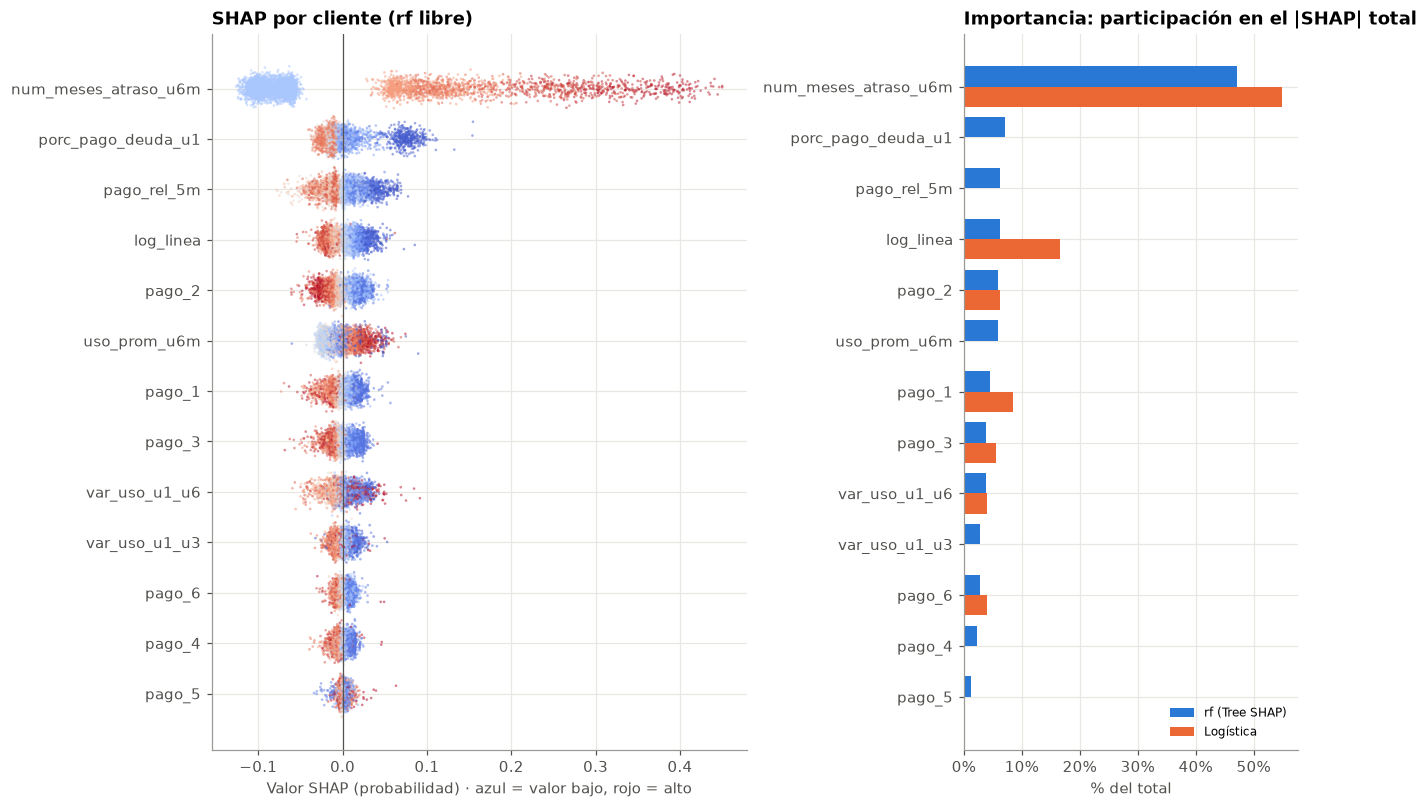

,rf (Tree SHAP) (%),Logística (%)
num_meses_atraso_u6m,47.2,54.9
porc_pago_deuda_u1,7.2,0.0
pago_rel_5m,6.3,0.0
log_linea,6.2,16.7
pago_2,5.9,6.2
uso_prom_u6m,5.8,0.0
pago_1,4.6,8.6
pago_3,3.9,5.5
var_uso_u1_u6,3.8,4.1
var_uso_u1_u3,2.9,0.0


,importancia,Spearman valor–SHAP,sentido SHAP,sentido esperado,coincide
num_meses_atraso_u6m,0.472,0.831,sube el riesgo,sube el riesgo,sí
porc_pago_deuda_u1,0.072,-0.706,baja el riesgo,baja el riesgo,sí
pago_rel_5m,0.063,-0.804,baja el riesgo,baja el riesgo,sí
log_linea,0.062,-0.911,baja el riesgo,baja el riesgo,sí
pago_2,0.059,-0.898,baja el riesgo,baja el riesgo,sí
uso_prom_u6m,0.058,0.426,sube el riesgo,sube el riesgo,sí
pago_1,0.046,-0.877,baja el riesgo,baja el riesgo,sí
pago_3,0.039,-0.872,baja el riesgo,baja el riesgo,sí
var_uso_u1_u6,0.038,-0.389,baja el riesgo,sin hipótesis,—
var_uso_u1_u3,0.029,-0.737,baja el riesgo,sin hipótesis,—


In [39]:
mejor_libre = clone(busquedas[MEJOR_FAMILIA].model.estimator).fit(X_ml, y_train)
muestra_shap, valores_mejor, shap_mejor = tabla_shap(mejor_libre, X_ml)
shap_arbol = pd.DataFrame(valores_mejor, columns=X_ml.columns, index=muestra_shap.index)

# Logística: con variables estandarizadas, la contribución de cada variable es coeficiente × valor estandarizado
# (el escalador se ajustó en train, así que la media de referencia es 0)
Z = modelo_baseline[0].transform(preparar(muestra_shap, VARIABLES_BASELINE))
shap_log = pd.DataFrame(Z * modelo_baseline[-1].coef_[0], columns=VARIABLES_BASELINE, index=muestra_shap.index)

# Las escalas no son comparables (Random Forest explica la probabilidad; la logística, el logit),
# así que las barras comparan la participación de cada variable en el total
unidad = 'logit' if MEJOR_FAMILIA in ('lgbm', 'xgboost') else 'probabilidad'
etiqueta = f'{MEJOR_FAMILIA} (Tree SHAP)'
importancia = pd.DataFrame({etiqueta: shap_arbol.abs().mean(),
                            'Logística': shap_log.abs().mean()}).fillna(0)
importancia = (importancia / importancia.sum()).sort_values(etiqueta)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 0.45 * len(importancia) + 1.6), gridspec_kw={'width_ratios': [1.6, 1]})
for i, v in enumerate(importancia.index):
    sv = shap_arbol[v].to_numpy()
    color = plt.cm.coolwarm(muestra_shap[v].rank(pct=True).to_numpy())
    jitter = np.random.default_rng(i).normal(0, 0.12, len(sv))
    a1.scatter(sv, i + jitter, c=color, s=3, alpha=0.5, linewidths=0)
a1.axvline(0, color=TINTA, linewidth=0.8)
a1.set_yticks(range(len(importancia))); a1.set_yticklabels(importancia.index)
a1.set(title=f'SHAP por cliente ({MEJOR_FAMILIA} libre)', xlabel=f'Valor SHAP ({unidad}) · azul = valor bajo, rojo = alto')

pos = np.arange(len(importancia))
a2.barh(pos + 0.2, importancia[etiqueta], height=0.4, color=AZUL, label=etiqueta)
a2.barh(pos - 0.2, importancia['Logística'], height=0.4, color=NARANJA, label='Logística')
a2.set_yticks(pos); a2.set_yticklabels(importancia.index)
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
a2.set(title='Importancia: participación en el |SHAP| total', xlabel='% del total'); a2.legend(fontsize=8, loc='lower right')
mostrar(fig, 'shap_mejor_vs_logistica')

display((importancia.iloc[::-1] * 100).round(1).rename(columns=lambda c: f'{c} (%)'))
shap_mejor.round(3)


- **En lo global, el Random Forest cumple:** en las 11 variables con hipótesis, el sentido de SHAP coincide con el esperado. El atraso concentra el 47 % de la importancia.
- **Pero algunas relaciones son débiles.** La correlación valor–SHAP de `uso_prom_u6m` y `pago_5` es de apenas 0.43, lo que sugiere tramos donde la relación se invierte. Para confirmarlo hace falta la prueba por cliente.

### 8.2 Prueba de monotonía y restricciones

Las variables con sentido esperado reciben una **restricción monotónica**: el modelo solo puede subir (+1) o bajar (−1) el riesgo cuando la variable sube. Las variables sin hipótesis quedan libres (0). Las cuatro familias admiten restricciones, así que se mide cuánto pierde cada una al aplicarlas y se repite la prueba de monotonía.

In [ ]:
MONOTONIA = {c: {SUBE: 1, BAJA: -1}.get(SENTIDO.get(c), 0) for c in VARIABLES_ML}

def con_restricciones(modelo, variables):
    signos = [MONOTONIA[c] for c in variables]
    if isinstance(modelo, LGBMClassifier):
        return clone(modelo).set_params(monotone_constraints=signos, monotone_constraints_method='advanced')
    if isinstance(modelo, XGBClassifier):
        return clone(modelo).set_params(monotone_constraints=tuple(signos))
    return clone(modelo).set_params(monotonic_cst=signos)

def prueba_monotonia(modelo, X, n=N_ICE, puntos=20):
    muestra = X.sample(n, random_state=SEMILLA)
    resultado = {}
    for c in X.columns:
        grilla = np.unique(np.quantile(X[c], np.linspace(0.01, 0.99, puntos)))
        copia = pd.concat([muestra] * len(grilla), ignore_index=True)
        copia[c] = np.repeat(grilla, len(muestra))
        saltos = np.diff(modelo.predict_proba(copia)[:, 1].reshape(len(grilla), len(muestra)), axis=0)
        signo = MONOTONIA.get(c, 0)
        if signo:
            resultado[c] = (signo * saltos < -1e-9).any(axis=0).mean()
        else:
            resultado[c] = ((saltos > 1e-9).any(axis=0) & (saltos < -1e-9).any(axis=0)).mean()
    return pd.Series(resultado)

restricciones, ice_libre, ice_restringido, oof_restringido = {}, {}, {}, {}
for estimador in ESTIMADORES:
    libre = busquedas[estimador].model.estimator
    restringido = con_restricciones(libre, VARIABLES_ML)
    oof_restringido[estimador] = fuera_de_pliegue_modelo(restringido, X_ml)
    ice_libre[estimador] = prueba_monotonia(clone(libre).fit(X_ml, y_train), X_ml)
    ice_restringido[estimador] = prueba_monotonia(clone(restringido).fit(X_ml, y_train), X_ml)
    con_hip = [c for c in VARIABLES_ML if MONOTONIA[c]]
    restricciones[estimador] = {'log loss libre': log_loss(y_train, oof_familias[estimador]),
                                'log loss con restricciones': log_loss(y_train, oof_restringido[estimador]),
                                'Gini libre': metricas(y_train, oof_familias[estimador])['Gini'],
                                'Gini con restricciones': metricas(y_train, oof_restringido[estimador])['Gini'],
                                'clientes en contra, libre': ice_libre[estimador][con_hip].mean(),
                                'clientes en contra, con restricciones': ice_restringido[estimador][con_hip].mean()}
restricciones = pd.DataFrame(restricciones).T.sort_values('log loss con restricciones')
FAMILIA_ELEGIDA = restricciones.index[0]
print(f'Familia con menor log loss una vez restringida: {FAMILIA_ELEGIDA}')
display(restricciones.round(4))
pd.DataFrame({'sentido esperado': [SENTIDO.get(c, 'sin hipótesis') for c in VARIABLES_ML],
              f'{MEJOR_FAMILIA} libre': ice_libre[MEJOR_FAMILIA], f'{FAMILIA_ELEGIDA} con restricciones': ice_restringido[FAMILIA_ELEGIDA]},
             index=VARIABLES_ML).round(3)

- **Los modelos libres no son monótonos.** En el Random Forest, mover una sola variable cambia la probabilidad en contra del sentido esperado en algún tramo para el 99 % a 100 % de los clientes en casi todas las variables. Por ejemplo, para casi todos los clientes existe algún tramo en que pagar más sube el riesgo. Le pasa también al 32 % de los clientes en el número de meses con atraso. En promedio, las variables con hipótesis van en contra en el 94 % de los clientes (Random Forest y LightGBM), el 88 % (XGBoost) y el 50 % (Extra Trees). Ese serrucho es ruido que el modelo aprendió y no se puede explicar a un cliente.
- **Con restricciones, ningún cliente tiene un tramo en contra en ninguna familia.** La prueba lo confirma en las 11 variables con hipótesis.
- **El costo de cumplir es muy distinto entre familias:**

  | Familia | Log loss libre → con restricciones | Gini libre → con restricciones |
  |---|---|---|
  | LightGBM | 0.4378 → 0.4398 | 0.550 → 0.547 |
  | XGBoost | 0.4377 → 0.4409 | 0.552 → 0.545 |
  | Random Forest | 0.4365 → 0.4504 | 0.554 → 0.537 |
  | Extra Trees | 0.4418 → 0.4567 | 0.538 → 0.509 |

  Los bosques promedian árboles profundos e independientes, y la restricción los limita mucho más que al *boosting*, que construye el modelo de a poco.
- **Se elige LightGBM con restricciones:** es el mejor modelo que cumple el sentido económico.
- **Las dos variaciones del uso no se pueden restringir** y su relación con el riesgo sube y baja en el 100 % de los clientes.

### 8.3 Variables sin hipótesis

Las dos variaciones del uso (`var_uso_u1_u6` y `var_uso_u1_u3`) no tienen un sentido esperado, así que no se pueden restringir. La última tabla muestra en qué proporción de clientes su relación con el riesgo sube y baja. Se retiran si el modelo sin ellas no es significativamente peor: el IC 95 % pareado de la diferencia de log loss debe incluir el cero.

In [ ]:
SIN_HIPOTESIS = [c for c in VARIABLES_ML if MONOTONIA[c] == 0]
con_hip = [c for c in VARIABLES_ML if MONOTONIA[c] != 0]
base_elegida = busquedas[FAMILIA_ELEGIDA].model.estimator
oof_sin_hip = fuera_de_pliegue_modelo(con_restricciones(base_elegida, con_hip), X_train[con_hip])
rep = bootstrap_log_loss(y_train, oof_restringido[FAMILIA_ELEGIDA], oof_sin_hip)
ic_dif = np.quantile(rep[:, 1] - rep[:, 0], [0.025, 0.975])
se_retiran = ic_dif[0] <= 0
VARIABLES_FINAL = con_hip if se_retiran else VARIABLES_ML
print(f'Log loss con las {len(VARIABLES_ML)} variables: {log_loss(y_train, oof_restringido[FAMILIA_ELEGIDA]):.4f} | '
      f'sin {SIN_HIPOTESIS}: {log_loss(y_train, oof_sin_hip):.4f} | diferencia IC 95 %: [{ic_dif[0]:.4f}, {ic_dif[1]:.4f}]')
print(f"{'Se retiran' if se_retiran else 'Se conservan'} | variables finales ({len(VARIABLES_FINAL)}): {VARIABLES_FINAL}")

- **Retirar las dos variaciones del uso no empeora el modelo:** el log loss pasa de 0.4398 a 0.4404, con un IC 95 % de la diferencia de −0.0004 a 0.0016, que incluye el cero. Se retiran.
- **Quedan 11 variables, todas con sentido esperado y restricción monotónica:** el atraso, la línea, el uso promedio, el porcentaje pagado de la deuda, el pago relativo de 5 meses y los seis pagos mensuales.

## 9. Ajuste fino con Optuna

**Sustento** FLAML compara familias con un presupuesto acotado. Optuna concentra la búsqueda en la familia elegida, ya con las restricciones monotónicas y las variables finales. Usa un muestreador bayesiano (TPE): cada prueba se elige con lo aprendido de las anteriores.

- **Objetivo:** log loss promedio en los 5 pliegues.
- **Punto de partida:** la primera prueba es la configuración de FLAML, así que el resultado no puede quedar peor que ella.
- **Espacio de búsqueda:** número de árboles, tasa de aprendizaje, hojas por árbol, mínimo de clientes por hoja, submuestreo de filas y columnas, y regularización L1 y L2.

In [ ]:
base_params = base_elegida.get_params()
signos_final = [MONOTONIA[c] for c in VARIABLES_FINAL]
X_final = X_train[VARIABLES_FINAL]

def modelo_lgbm(**p):
    return LGBMClassifier(**p, subsample_freq=1, monotone_constraints=signos_final, monotone_constraints_method='advanced',
                          random_state=SEMILLA, n_jobs=-1, verbose=-1)

def objetivo(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 100, 1000),
             learning_rate=trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
             num_leaves=trial.suggest_int('num_leaves', 4, 64, log=True),
             min_child_samples=trial.suggest_int('min_child_samples', 5, 300, log=True),
             subsample=trial.suggest_float('subsample', 0.5, 1.0),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
             reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
             reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True))
    return log_loss(y_train, fuera_de_pliegue_modelo(modelo_lgbm(**p), X_final))

assert FAMILIA_ELEGIDA == 'lgbm', 'El espacio de búsqueda está definido para LightGBM'
estudio = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.enqueue_trial({k: base_params[k] for k in ['n_estimators', 'learning_rate', 'num_leaves', 'min_child_samples',
                                                   'colsample_bytree', 'reg_alpha', 'reg_lambda']} | {'subsample': 1.0})
estudio.optimize(objetivo, n_trials=N_TRIALS_OPTUNA)

modelo_final = modelo_lgbm(**estudio.best_params)
oof_final = fuera_de_pliegue_modelo(modelo_final, X_final)
print(f'Log loss: configuración de FLAML {estudio.trials[0].value:.4f} → mejor de Optuna {estudio.best_value:.4f} '
      f'(prueba {estudio.best_trial.number + 1} de {N_TRIALS_OPTUNA})')
pd.Series(estudio.best_params).to_frame('valor').T

- **Optuna mejora poco:** el log loss baja de 0.4407 (la configuración de FLAML sobre las 11 variables) a 0.4401. FLAML ya había encontrado una zona buena, y Optuna confirma que no hay mucho más por ganar con estos datos.
- **La configuración elegida es más conservadora:** 426 árboles con una tasa de aprendizaje baja (0.009), 47 hojas y al menos 30 clientes por hoja. Es un modelo que avanza en pasos pequeños.

## 10. Modelo final frente al baseline

### 10.1 Calibración

Misma revisión que en 6.3. Además se prueba una recalibración isotónica ajustada fuera de pliegue: para cada pliegue, se ajusta con las predicciones de los otros cuatro. Solo se aplica si mejora el Brier.

In [ ]:
oof_isotonica = np.zeros(len(y_train))
for ajuste, valida in pliegues:
    oof_isotonica[valida] = IsotonicRegression(out_of_bounds='clip').fit(oof_final[ajuste], y_train[ajuste]).predict(oof_final[valida])
RECALIBRAR = brier_score_loss(y_train, oof_isotonica) < brier_score_loss(y_train, oof_final)

logit_final = np.log(oof_final / (1 - oof_final)).reshape(-1, 1)
pendiente = LogisticRegression(penalty=None).fit(logit_final, y_train).coef_[0, 0]
decil_final = pd.qcut(oof_final, 10, labels=False) + 1
calibracion_final = pd.DataFrame({'probabilidad media': pd.Series(oof_final).groupby(decil_final).mean(),
                                  'tasa observada': pd.Series(y_train).groupby(decil_final).mean()})
calibracion_final['diferencia'] = calibracion_final['tasa observada'] - calibracion_final['probabilidad media']
calibracion_final['diferencia en la logística'] = calibracion['diferencia'].to_numpy()
calibracion_final.index.name = 'decil de riesgo'
print(f'Probabilidad media {oof_final.mean():.4f} frente a π = {y_train.mean():.4f} | pendiente {pendiente:.3f} | '
      f'Brier {brier_score_loss(y_train, oof_final):.5f} sin recalibrar y {brier_score_loss(y_train, oof_isotonica):.5f} con isotónica → '
      f"{'se recalibra' if RECALIBRAR else 'no se recalibra'}")
calibracion_final.round(4)

- **Calibrado también por decil, no solo en el agregado.** La probabilidad media (0.2216) coincide con π y la pendiente es 1.014. En 9 de los 10 deciles la diferencia entre lo predicho y lo observado es de 0.7 puntos o menos; solo el decil 9 llega a 1.8.
- **Corrige el patrón en S de la logística,** que llegaba a 5.4 puntos. Alrededor del corte de 1/6 (decil 6) la diferencia es de 0.7 puntos, así que el corte de costo se puede aplicar directamente.
- **No se recalibra:** la isotónica empeora el Brier (0.13994 frente a 0.13965).

### 10.2 Comparación y elección

**Regla, fijada antes de comparar:** el modelo final reemplaza a la logística solo si mejora el Gini **y** el costo por cliente, con intervalos pareados de 95 % que excluyen el cero. Si no, se queda la logística, que es más simple de explicar y mantener.

In [ ]:
rep_base, rep_final = replicas_bootstrap(y_train, oof_baseline, oof_final)
claves_eleccion = ['Gini', 'KS', 'PR AUC', 'Brier', 'recall @10%', 'marcados al corte', 'recall al corte', 'precisión al corte', 'costo por cliente']
eleccion = pd.DataFrame({'logística': pd.Series(metricas(y_train, oof_baseline))[claves_eleccion],
                         'LightGBM final': pd.Series(metricas(y_train, oof_final))[claves_eleccion]})
eleccion['diferencia'] = eleccion['LightGBM final'] - eleccion['logística']
eleccion['IC 95 % inf.'] = (rep_final - rep_base)[claves_eleccion].quantile(0.025)
eleccion['IC 95 % sup.'] = (rep_final - rep_base)[claves_eleccion].quantile(0.975)
GANA_FINAL = (eleccion.loc['Gini', 'IC 95 % inf.'] > 0) and (eleccion.loc['costo por cliente', 'IC 95 % sup.'] < 0)
print(f"Modelo elegido: {'LightGBM final' if GANA_FINAL else 'logística'}")
eleccion.round(4)

- **Se elige LightGBM:** mejora el Gini en 0.025 (IC 0.019 a 0.031) y baja el costo por cliente en 0.020 (IC 0.010 a 0.028). Cumple las dos condiciones de la regla.
- **Mejora también KS (+0.029), PR AUC (+0.010) y Brier (−0.004),** todas con intervalos que excluyen el cero.
- **De dónde sale el ahorro:** al corte de 1/6 marca 2.4 puntos más de clientes (45.1 % frente a 42.7 %) y captura 3.3 puntos más de los impagos (75.8 % frente a 72.5 %), con casi la misma precisión. Con un FN cinco veces más caro que un FP, detectar más impagos compensa marcar a algunos clientes más.
- **En el 10 % de mayor riesgo los dos modelos son iguales** (recall 28.4 % frente a 28.6 %). La ganancia está en el ordenamiento de la zona media, justo donde está el corte.

### 10.3 Explicación del modelo final

El gráfico de la izquierda (*beeswarm*) muestra un punto por cliente y variable. La posición horizontal es cuánto sube (derecha) o baja (izquierda) el riesgo esa variable para ese cliente, y el color es el valor de la variable (rojo alto, azul bajo). A la derecha, la relación entre el valor de las cuatro variables más importantes y su SHAP.

In [ ]:
modelo_final_ajustado = clone(modelo_final).fit(X_final, y_train)
muestra_shap, valores_shap, shap_final = tabla_shap(modelo_final_ajustado, X_final)
fig = plt.figure(figsize=(8, 5))
shap.summary_plot(valores_shap, muestra_shap, show=False, plot_size=None, max_display=len(VARIABLES_FINAL))
fig.axes[0].set_title('Contribución de cada variable al riesgo (SHAP)')
fig.axes[0].set_xlabel('SHAP (log-odds): a la derecha sube el riesgo')
fig.axes[-1].set_ylabel('valor de la variable')
fig.axes[-1].set_yticklabels(['bajo', 'alto'])
mostrar(fig, 'shap_beeswarm')

principales = shap_final.index[:4]
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, c in zip(ejes, principales):
    j = list(X_final.columns).index(c)
    es_pago = c.startswith('pago_')
    x = np.log1p(muestra_shap[c]) if es_pago else muestra_shap[c]
    ax.scatter(x, valores_shap[:, j], s=8, alpha=0.35, color=AZUL, linewidths=0)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel('log(1 + pago en NT$)' if es_pago else 'valor de la variable')
ejes[0].set_ylabel('SHAP (log-odds)')
fig.suptitle('Cada variable mueve el riesgo en un solo sentido', x=0.01, ha='left', fontweight='bold')
mostrar(fig, 'shap_dependencia')

ganancia = pd.Series(modelo_final_ajustado.booster_.feature_importance('gain'), index=VARIABLES_FINAL)
shap_final['% del Gain'] = ganancia / ganancia.sum()
print(f"Mayor participación en el Gain: {shap_final['% del Gain'].idxmax()} con {pct(shap_final['% del Gain'].max())} "
      f"(tope de referencia de la guía para crédito individual: 30 %, hasta 35 % con justificación)")
shap_final.round(3)

- **Las 11 variables mueven el riesgo en el sentido esperado,** con correlaciones valor–SHAP de 0.68 a 0.96 en valor absoluto.
- **El atraso es lo que más pesa:** sin meses con atraso, el SHAP es de −0.55 (log-odds). Con un mes sube a cerca de +0.6 y con seis llega a +2.0. Cada mes adicional suma, pero el salto más grande es el primero.
- **El uso de la línea actúa como umbral:** por debajo de un uso promedio del 50 % casi no aporta. Por encima, sube el riesgo.
- **En los pagos importa pagar algo relevante:** el riesgo baja por escalones al pasar de pagos nulos o pequeños (menos de unos 1,500 NT$) a pagos de hasta unos 15,000 NT$, y después se estabiliza. Pagar mucho más no sigue bajando el riesgo.
- **Concentración por encima de la guía:** el atraso explica el 47.7 % de la importancia SHAP y el 76.7 % del *Gain*. La guía usa como referencia un tope de 30 % para crédito individual, con hasta 5 puntos adicionales si se justifica. El *Gain* exagera la concentración, porque los primeros cortes de cada árbol usan la variable más fuerte, pero incluso con SHAP se supera el tope. Es una excepción que hay que documentar: el evento (impago el mes siguiente) depende por naturaleza del atraso actual, y esa variable sola tiene un Gini de 0.462, frente a 0.544 del modelo completo. La consecuencia práctica es que el modelo depende mucho de cómo se registra el atraso, así que su codificación es lo primero que hay que vigilar.

### 10.4 ¿Aporta el modelo más que una regla de atraso?

El atraso concentra cerca de la mitad de la importancia. Hay que verificar que el modelo no sea, en la práctica, una regla simple que el negocio podría aplicar sin modelo: **reducir la línea a quien tuvo algún mes con atraso en los últimos seis**. Se compara en dos frentes, con las predicciones fuera de pliegue de train:

- **Gini por segmento:** dentro de los clientes sin atraso, el atraso no ordena nada. Si el modelo separa bien ahí, es gracias al resto de variables.
- **Costo:** modelo al corte de 1/6 frente a la regla, con un intervalo pareado de la diferencia de costo por cliente.

In [ ]:
def costo_cliente(y, marcado):
    # Costo de cada cliente: FN = 5 si cae en impago y no se le redujo la línea; FP = 1 si se le redujo sin caer
    return COSTO_FN * (~marcado & (y == 1)) + COSTO_FP * (marcado & (y == 0))

gini = lambda y, p: 2 * roc_auc_score(y, p) - 1
atraso_train = X_train['num_meses_atraso_u6m'].to_numpy()
segmentos = {'sin atraso en 6 meses': atraso_train == 0, 'con algún atraso': atraso_train > 0, 'todos': np.ones(len(y_train), bool)}
marcado_modelo = oof_final > UMBRAL_COSTO
aporte = pd.DataFrame({n: {'% de clientes': s.mean(), 'tasa de impago': y_train[s].mean(), '% de los impagos': y_train[s].sum() / y_train.sum(),
                           'Gini LightGBM': gini(y_train[s], oof_final[s]), 'Gini logística': gini(y_train[s], oof_baseline[s]),
                           '% marcados por el modelo': marcado_modelo[s].mean(),
                           'recall del modelo': marcado_modelo[s & (y_train == 1)].sum() / (s & (y_train == 1)).sum()}
                       for n, s in segmentos.items()}).T
display(aporte.round(3))

marcado_regla = atraso_train > 0
diferencia_costo = costo_cliente(y_train, marcado_modelo) - costo_cliente(y_train, marcado_regla)
rng = np.random.default_rng(SEMILLA)
replicas = [diferencia_costo[rng.integers(0, len(y_train), len(y_train))].mean() for _ in range(N_BOOTSTRAP)]
frente_regla = pd.DataFrame({
    'regla: reducir si tuvo atraso': {'% de clientes reducidos': marcado_regla.mean(), 'recall': y_train[marcado_regla].sum() / y_train.sum(),
                                      'precisión': y_train[marcado_regla].mean(), 'costo por cliente': costo_cliente(y_train, marcado_regla).mean()},
    'LightGBM (p > 1/6)': {'% de clientes reducidos': marcado_modelo.mean(), 'recall': y_train[marcado_modelo].sum() / y_train.sum(),
                           'precisión': y_train[marcado_modelo].mean(), 'costo por cliente': costo_cliente(y_train, marcado_modelo).mean()}}).T
print(f'Diferencia de costo por cliente (modelo − regla): {diferencia_costo.mean():.4f} | '
      f'IC 95 % [{np.quantile(replicas, 0.025):.4f}, {np.quantile(replicas, 0.975):.4f}]')
frente_regla.round(4)

- **Un tercio de los impagos viene de clientes sin ningún atraso.** Son el 66 % de la cartera, con una tasa de impago de 11.5 %, y aportan el 34 % de los impagos. Una regla de atraso no los ve nunca.
- **Ahí está el valor del modelo.** Entre los clientes sin atraso, LightGBM ordena con un Gini de 0.278 (la logística, 0.240), usando solo pagos, uso y línea. Reduce la línea al 18.5 % de ellos y anticipa el 31 % de sus impagos.
- **Entre los clientes con atraso, el modelo se comporta casi como la regla:** reduce al 97 % y captura el 99 % de sus impagos.
- **Frente a la regla, el modelo baja el costo en 0.020 por cliente** (IC 95 % pareado de −0.031 a −0.010). Reduce la línea a más clientes (45.1 % frente a 33.8 %), pero captura 10 puntos más de los impagos (75.8 % frente a 65.7 %).
- **La logística no le gana a la regla:** su costo (0.571) es igual al de la regla (0.572). Esta es la razón de fondo para usar LightGBM y no la logística.
- **Respuesta a la concentración:** que el atraso pese cerca del 50 % es esperable a un mes de horizonte, pero el modelo aporta justo donde el atraso no puede ayudar.

### 10.5 Evaluación en test

Es la primera y única vez que se usa el test. Los dos modelos se ajustan con todo train, con las variables, restricciones y parámetros ya decididos, y se evalúan sobre los 9,000 clientes de test con las mismas métricas y el mismo corte de 1/6. Las diferencias llevan intervalos pareados por bootstrap.

In [ ]:
p_test_baseline = modelo_baseline.predict_proba(preparar(X_test, VARIABLES_BASELINE))[:, 1]
p_test_final = modelo_final_ajustado.predict_proba(X_test[VARIABLES_FINAL])[:, 1]
rep_tb, rep_tf = replicas_bootstrap(y_test, p_test_baseline, p_test_final)
prueba = pd.DataFrame({'logística': pd.Series(metricas(y_test, p_test_baseline))[claves_eleccion],
                       'LightGBM final': pd.Series(metricas(y_test, p_test_final))[claves_eleccion]})
prueba['diferencia'] = prueba['LightGBM final'] - prueba['logística']
prueba['IC 95 % inf.'] = (rep_tf - rep_tb)[claves_eleccion].quantile(0.025)
prueba['IC 95 % sup.'] = (rep_tf - rep_tb)[claves_eleccion].quantile(0.975)
prueba['LightGBM fuera de pliegue (train)'] = eleccion['LightGBM final']
print(f'Test: {len(y_test):,} clientes, π = {y_test.mean():.4f} | probabilidad media del final {p_test_final.mean():.4f}')
prueba.round(4)

- **En test, LightGBM también le gana a la logística:** Gini 0.527 frente a 0.499 (+0.028, IC 0.019 a 0.037) y costo por cliente 0.567 frente a 0.596 (−0.028, IC 0.014 a 0.043). Las conclusiones de train se mantienen.
- **Los dos modelos bajan un poco frente a train:** el Gini de LightGBM pasa de 0.544 a 0.527 y el de la logística, de 0.519 a 0.499. Como la caída es parecida en ambos, se explica por la muestra y no por un sobreajuste propio del *boosting*. El Gini de test sigue sobre el rango de referencia de 40 % a 50 %.
- **La calibración se mantiene:** la probabilidad media en test (0.2212) es igual a la tasa de impago. El Brier es 0.142.
- **Al corte de 1/6 en test:** se marca al 44.9 % y se captura el 74.4 % de los impagos.

## 11. Estrategia de reducción de líneas

**Sustento** Con FN = 5 y FP = 1, reducir la línea conviene cuando el costo esperado de no hacerlo, 5 × p, supera el de hacerlo, 1 × (1 − p), es decir, cuando p > 1/6. Ese corte vale solo si la probabilidad está bien calibrada, como se comprobó en 10.1. Antes de aplicarlo se verifica con la curva de costo fuera de pliegue (train) que 1/6 esté cerca del mínimo empírico, y después se traduce a clientes, impagos y montos de línea en test.

In [ ]:
cortes = np.linspace(0.02, 0.60, 59)
def costo_por_corte(y, p):
    return np.array([(COSTO_FN * ((p <= c) & (y == 1)).sum() + COSTO_FP * ((p > c) & (y == 0)).sum()) / len(y) for c in cortes])
costo_base, costo_final = costo_por_corte(y_train, oof_baseline), costo_por_corte(y_train, oof_final)
corte_empirico = cortes[costo_final.argmin()]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(cortes, costo_base, color=GRIS, label='logística')
ax.plot(cortes, costo_final, color=AZUL, label='LightGBM final')
ax.axvline(UMBRAL_COSTO, color=TINTA, lw=1, ls='--')
ax.annotate('corte 1/6', (UMBRAL_COSTO, costo_final.max()), xytext=(5, -2), textcoords='offset points', fontsize=9, color=TINTA, va='top')
ax.set_xlabel('corte de probabilidad'); ax.set_ylabel('costo por cliente (train, fuera de pliegue)')
ax.set_title('El costo mínimo está alrededor de 1/6')
ax.legend()
mostrar(fig, 'curva_costo')
print(f'Corte de mínimo costo empírico (LightGBM, train): {corte_empirico:.2f} con costo {costo_final.min():.4f} | '
      f'al corte 1/6: {costo_final[np.abs(cortes - UMBRAL_COSTO).argmin()]:.4f}')

- **La teoría y los datos coinciden:** el corte de mínimo costo empírico de LightGBM es 0.17, prácticamente 1/6, con el mismo costo (0.552).
- **La curva es plana cerca del mínimo:** entre 0.13 y 0.20 el costo cambia poco. Si el negocio necesita marcar menos clientes, puede subir algo el corte sin perder mucho.
- **LightGBM está por debajo de la logística en todos los cortes relevantes.**

### 11.1 Alternativas para el negocio

Antes de recomendar el modelo, se compara con las otras decisiones que el negocio podría tomar, todas sobre los mismos 9,000 clientes de test:

- **No reducir a nadie** y **reducir a todos:** los dos extremos.
- **Regla de atraso:** reducir a quien tuvo algún mes con atraso.
- **Logística** y **LightGBM:** reducir si la probabilidad supera 1/6.

Además del costo, se mide lo que le importa al negocio en montos:

- **Línea de impagos alcanzada:** qué parte de la línea de los clientes que caen en impago queda bajo reducción. Es la exposición que se protege.
- **Línea de buenos clientes afectada:** qué parte de la línea de los clientes que pagan se recorta. Es el costo comercial: menos consumo, peor experiencia y riesgo de que el cliente se vaya.

In [ ]:
linea_test = X_test['linea'].to_numpy()
atraso_test = X_test['num_meses_atraso_u6m'].to_numpy()
impago, bueno = y_test == 1, y_test == 0
alternativas = {'no reducir a nadie': np.zeros(len(y_test), bool), 'reducir a todos': np.ones(len(y_test), bool),
                'regla: tuvo algún atraso': atraso_test > 0, 'logística (p > 1/6)': p_test_baseline > UMBRAL_COSTO,
                'LightGBM (p > 1/6)': p_test_final > UMBRAL_COSTO}
costo_no_actuar = costo_cliente(y_test, alternativas['no reducir a nadie']).mean()
negocio = pd.DataFrame({n: {'clientes reducidos': m.sum(), '% de clientes': m.mean(),
                            'impagos anticipados': (m & impago).sum(), 'recall': (m & impago).sum() / impago.sum(),
                            'buenos clientes afectados': (m & bueno).sum(), '% de buenos afectados': (m & bueno).sum() / bueno.sum(),
                            'línea de impagos alcanzada': linea_test[m & impago].sum() / linea_test[impago].sum(),
                            'línea de buenos afectada': linea_test[m & bueno].sum() / linea_test[bueno].sum(),
                            'costo por cliente': costo_cliente(y_test, m).mean(),
                            'ahorro frente a no actuar': 1 - costo_cliente(y_test, m).mean() / costo_no_actuar}
                        for n, m in alternativas.items()}).T
negocio.round(3)

- **LightGBM es la alternativa de menor costo:** 0.567 por cliente, un **48.7 % menos que no actuar**, frente a 46.1 % de la logística, 45.4 % de la regla de atraso y 29.6 % de reducir a todos.
- **Lo que logra en 9,000 clientes:** reduce la línea a 4,044 (44.9 %) y anticipa 1,482 de los 1,991 impagos (74.4 %). Queda bajo reducción el **65.9 % de la línea** de los clientes que caen en impago.
- **Lo que cuesta:** afecta a 2,562 buenos clientes (36.6 % de los que pagan) y al 25.6 % de su línea.
- **Frente a la regla de atraso, el análisis marginal justifica el modelo:** reduce la línea a 1,065 clientes más, de los cuales 232 caen en impago. Esa precisión marginal (21.8 %) supera el 1/6 (16.7 %) que hace rentable reducir con la relación 5 a 1. Es decir, cada reducción adicional que propone el modelo, en promedio, paga su costo.
- **Frente a la logística:** con 219 reducciones más, anticipa 79 impagos más y alcanza 6.6 puntos más de la línea en riesgo.

### 11.2 Bandas de riesgo y clientes afectados

Se proponen tres bandas sobre la probabilidad del modelo final:

| Banda | Probabilidad | Acción |
|---|---|---|
| **Baja** | ≤ 1/6 | Mantener la línea |
| **Media** | > 1/6 y ≤ 0.50 | Reducir la línea |
| **Alta** | > 0.50 | Reducir la línea y priorizar contacto preventivo (el impago es más probable que el pago) |

El corte de 0.50 no sale de los costos: es una regla de prioridad operativa. Las cifras son de test. Para la cartera completa se escalan a 30,000 clientes con las mismas proporciones.

In [ ]:
BANDAS = [0, UMBRAL_COSTO, 0.50, 1]
NOMBRES = ['baja: mantener', 'media: reducir', 'alta: reducir y contactar']
banda = pd.cut(p_test_final, BANDAS, labels=NOMBRES, include_lowest=True)
linea_test = X_test['linea'].to_numpy()
estrategia = pd.DataFrame({
    'clientes (test)': pd.Series(1, index=banda).groupby(banda, observed=False).sum(),
    'probabilidad media': pd.Series(p_test_final).groupby(banda, observed=False).mean().to_numpy(),
    'tasa de impago observada': pd.Series(y_test).groupby(banda, observed=False).mean().to_numpy(),
    'impagos': pd.Series(y_test).groupby(banda, observed=False).sum().to_numpy(),
    'línea total (millones NT$)': pd.Series(linea_test).groupby(banda, observed=False).sum().to_numpy() / 1e6})
estrategia['% de clientes'] = estrategia['clientes (test)'] / len(y_test)
estrategia['% de los impagos'] = estrategia['impagos'] / y_test.sum()
estrategia['% de la línea'] = estrategia['línea total (millones NT$)'] / estrategia['línea total (millones NT$)'].sum()
estrategia['clientes en cartera de 30,000'] = (estrategia['% de clientes'] * len(datos)).round(-1).astype(int)
marcados = p_test_final > UMBRAL_COSTO
print(f'Se reduce la línea a {marcados.sum():,} de {len(y_test):,} clientes de test ({pct(marcados.mean())}) | '
      f'capturan {pct(y_test[marcados].sum() / y_test.sum())} de los impagos | '
      f'{pct(1 - y_test[marcados].mean())} de los marcados no habría caído en impago')
estrategia.round(3)

- **Reducir la línea a 4,044 de 9,000 clientes de test (44.9 %).** Escalado a la cartera de 30,000, son unos 13,500 clientes: 10,280 en la banda media y 3,200 en la alta.
- **Se capturan 3 de cada 4 impagos (74.4 %).** El 29.5 % de los impagos está en la banda alta, que es solo el 10.7 % de los clientes.
- **El precio es reducir la línea a buenos clientes:** el 63.4 % de los marcados no habría caído en impago. Es la consecuencia directa de que un impago no detectado cueste 5 veces más.
- **La probabilidad del modelo coincide con la tasa observada en cada banda:** 0.100 frente a 10.3 %, 0.292 frente a 29.0 % y 0.619 frente a 61.2 %.
- **La reducción afecta solo al 32.7 % del monto de línea.** Los clientes de mayor riesgo tienen líneas más chicas: la banda alta concentra el 10.7 % de los clientes y el 5.6 % de la línea.

### 11.3 Sensibilidad al supuesto de costos

La relación 5 a 1 (un impago no detectado cuesta cinco veces más que reducir la línea a un buen cliente) es un supuesto del negocio, no una pérdida medida. Como el modelo está calibrado, cambiar el supuesto solo cambia el corte, a $1 / (1 + r)$ para una relación de $r$ a 1, sin reentrenar. La tabla muestra qué implica cada supuesto en test, para que el negocio elija con conocimiento de causa.

In [ ]:
sensibilidad = {}
for r in [2, 3, 5, 8, 10]:
    corte = 1 / (1 + r)
    m = p_test_final > corte
    sensibilidad[f'{r} a 1'] = {'corte': corte, '% de clientes reducidos': m.mean(), 'clientes en cartera de 30,000': int(round(m.mean() * len(datos), -1)),
                                'recall': (m & impago).sum() / impago.sum(), 'precisión': y_test[m].mean(),
                                '% de buenos afectados': (m & bueno).sum() / bueno.sum(),
                                'línea de impagos alcanzada': linea_test[m & impago].sum() / linea_test[impago].sum()}
pd.DataFrame(sensibilidad).T.round(3)

- **La decisión depende mucho del supuesto de costos.** Con 5 a 1 se reduce la línea al 44.9 % de los clientes (~13,500 de 30,000). Con 3 a 1, al 28.8 % (~8,600), capturando el 59.6 % de los impagos. Con 10 a 1, al 76.8 % (~23,000).
- **Cada supuesto tiene un costo comercial distinto:** el porcentaje de buenos clientes afectados va de 14.6 % (2 a 1) a 72.0 % (10 a 1).
- **El negocio tiene que validar la relación 5 a 1 con datos de pérdida:** la pérdida de un impago (saldo que no se recupera) frente a lo que se deja de ganar al reducir la línea a un buen cliente (menor consumo, intereses, riesgo de que se vaya). Como el modelo está calibrado, ajustar el supuesto solo cambia el corte, sin reentrenar.

### 11.4 Equidad

Las variables protegidas no entran al modelo, pero otras variables pueden funcionar como sustitutos. Se compara, por grupo y en test, la proporción de clientes con línea reducida, la tasa de impago real, el recall (impagos detectados) y la tasa de falsos positivos (buenos clientes a los que se les reduce la línea).

In [ ]:
datos_test = datos.iloc[idx_test]
grupos = {'sexo': datos_test['sexo'].map({1: 'hombre', 2: 'mujer'}),
          'edad': pd.cut(datos_test['edad'], [0, 29, 45, 120], labels=['hasta 29', '30 a 45', 'más de 45'])}
filas = []
for nombre, g in grupos.items():
    for valor in g.dropna().unique():
        en = (g == valor).to_numpy()
        y_g, m_g = y_test[en], marcados[en]
        filas.append({'variable': nombre, 'grupo': valor, 'clientes': en.sum(), 'tasa de impago': y_g.mean(),
                      '% con línea reducida': m_g.mean(), 'recall': m_g[y_g == 1].mean(),
                      'falsos positivos (% de buenos)': m_g[y_g == 0].mean()})
pd.DataFrame(filas).set_index(['variable', 'grupo']).sort_index().round(3)

- **Por sexo no hay brecha relevante:** el recall es igual (74.4 % y 74.5 %) y la tasa de falsos positivos difiere en 2.8 puntos (38.3 % en hombres y 35.5 % en mujeres), en línea con la tasa de impago, que es mayor en hombres.
- **Por edad sí hay una brecha que vigilar.** A los menores de 30 se les reduce la línea más seguido (48.8 % frente a 41.7 % de 30 a 45). Entre los buenos clientes, a los jóvenes se les reduce la línea en el 40.4 % de los casos, frente al 33.9 %: 6.5 puntos más. Su tasa de impago es apenas mayor (22.4 % frente a 20.6 %), así que el riesgo no explica toda la diferencia.
- **Posible sustituto:** la edad no está en el modelo, pero la línea puede funcionar como sustituto. Los menores de 30 tienen una línea mediana de 90,000 NT$, la mitad que los de 30 a 45 (180,000), y una línea más baja sube el riesgo en el modelo. Antes de implementar conviene decidir si la brecha es aceptable o si hay que corregirla.

## 12. Conclusiones y recomendación al negocio

**Recomendación:** usar el modelo LightGBM para decidir la reducción de líneas, reduciendo a los clientes con probabilidad de impago mayor a 1/6. Hacerlo en dos fases y validar antes el supuesto de costos.

### Por qué este modelo

| Criterio | Evidencia (test, 9,000 clientes) |
|---|---|
| **Ordena mejor el riesgo** | Gini 0.527 frente a 0.499 de la logística (+0.028, IC 0.019 a 0.037) |
| **Cuesta menos que cualquier alternativa** | 0.567 por cliente: 48.7 % menos que no actuar, frente a 46.1 % de la logística y 45.4 % de la regla de atraso |
| **Aporta más que una regla simple** | Detecta impagos entre los clientes sin atraso (Gini 0.278), que aportan un tercio de los impagos y que una regla de atraso no ve |
| **Sus probabilidades son confiables** | Calibrado por decil (diferencias ≤ 0.7 puntos en 9 de 10 deciles), así que el corte de costo se aplica directo |
| **Se puede explicar** | Las 11 variables mueven el riesgo en el sentido del negocio para todos los clientes (restricciones monotónicas, verificadas con la prueba por cliente) |

### Qué implica en la cartera (30,000 clientes)

| Banda | Probabilidad | Acción | Clientes | Tasa de impago | % de los impagos |
|---|---|---|---|---|---|
| Baja | ≤ 1/6 | Mantener la línea | ~16,500 | 10 % | 26 % |
| Media | 1/6 a 0.50 | Reducir la línea | ~10,300 | 29 % | 45 % |
| Alta | > 0.50 | Reducir y contacto preventivo | ~3,200 | 61 % | 30 % |

Se reduce la línea a ~13,500 clientes y se anticipan 3 de cada 4 impagos. Queda bajo reducción el 66 % de la línea en riesgo y se afecta al 26 % de la línea de los buenos clientes.

### Cómo implementarlo

1. **Validar la relación 5 a 1** con finanzas, usando la pérdida real por impago y el margen que se pierde por cliente. Con 3 a 1 se reduciría a ~8,600 clientes en lugar de ~13,500.
2. **Fase 1, banda alta (~3,200 clientes):** 6 de cada 10 caen en impago, así que el costo comercial es bajo y el beneficio, inmediato. Incluir un **grupo de control** sin reducción para medir si reducir la línea realmente evita el impago o solo lo adelanta. Estos datos no lo pueden responder.
3. **Fase 2, banda media (~10,300 clientes):** extenderla con lo medido en la fase 1. Conviene evaluar reducciones parciales, proporcionales al riesgo, para cuidar a los buenos clientes de esta banda (71 % no cae en impago).

### Controles antes y después de implementar

- **Codificación del atraso:** el código de 1 mes de atraso solo existe en septiembre. Hay que confirmar con la fuente cómo se registra en producción, porque el atraso concentra el 77 % del *Gain* (por encima del tope de la guía, como excepción documentada).
- **Estabilidad:** vigilar mensualmente el PSI de la probabilidad, de `pago_1`, `pago_2` y `porc_pago_deuda_u1`, y la tasa de impago por banda.
- **Equidad por edad:** a los buenos clientes menores de 30 se les reduce la línea 6.5 puntos más seguido que a los de 30 a 45, probablemente porque tienen líneas más bajas. Decidir si se acepta o se corrige antes de la fase 2.

### Lo que estos datos no permiten validar

- **Desempeño fuera de tiempo:** solo hay un mes de objetivo.
- **El efecto causal de la reducción:** lo mide el grupo de control de la fase 1.
- **La pérdida real:** la relación 5 a 1 es un supuesto que el negocio tiene que validar.